边界元法BEM参考解

=== 多核满血版纯 BEM 求解二维弹性受压方板 ===
E = 1.0e+06 Pa, nu = 0.3, 网格数 N = 800
正在编译并多核组装矩阵...
H, G 矩阵组装完成，耗时: 1.129 s
线性方程组求逆完成，耗时: 0.047 s 
正在多核全速计算域内物理场 (含4倍有限差分)...
全域位移与偏导数提取完成，耗时: 2.052 s 


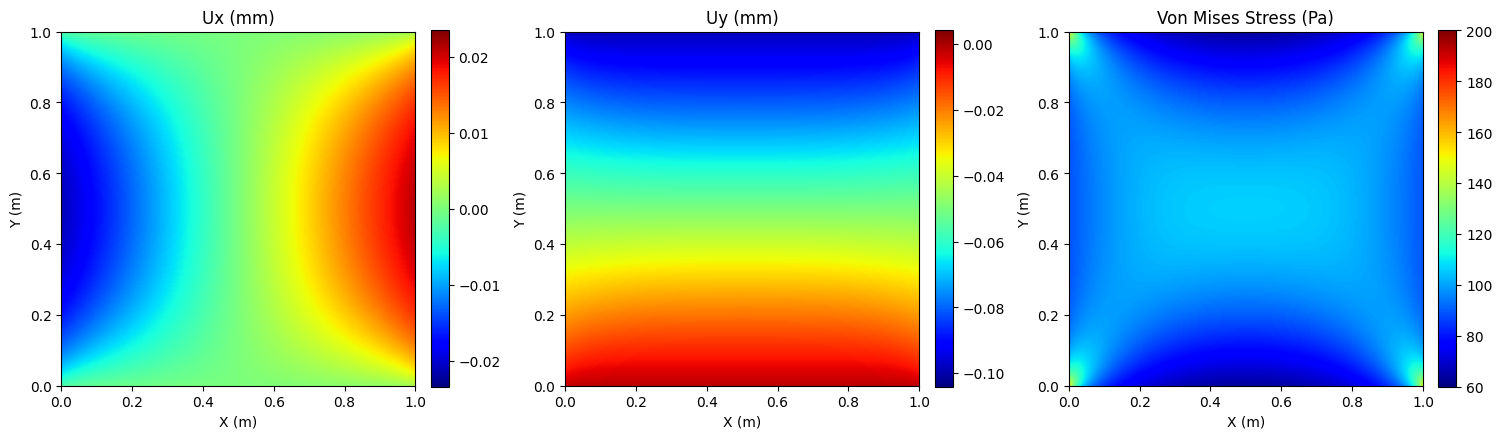

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数
# ==========================================
L = 1.0              # 正方形边长 (m)
E = 1.0e6            # 杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top = -1e-4     # 顶边法向位移 (m)

nu_eff = nu 
G_shear = E / (2.0 * (1.0 + nu))

n_per_side = 200      # 每边单元数 (总数 N = 800)
N = n_per_side * 4

print(f"=== 多核满血版纯 BEM 求解二维弹性受压方板 ===")
print(f"E = {E:.1e} Pa, nu = {nu}, 网格数 N = {N}")

# ==========================================
# 2. 生成常数边界单元网格
# ==========================================
nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
edge_ids = np.zeros(N, dtype=int)

dl = L / n_per_side
coords = np.linspace(dl/2, L - dl/2, n_per_side)

idx = 0
for x in coords:
    nodes[idx] = [x, 0]; normals[idx] = [0, -1]; lengths[idx] = dl; edge_ids[idx] = 0; idx += 1
for y in coords:
    nodes[idx] = [L, y]; normals[idx] = [1, 0]; lengths[idx] = dl; edge_ids[idx] = 1; idx += 1
for x in coords[::-1]:
    nodes[idx] = [x, L]; normals[idx] = [0, 1]; lengths[idx] = dl; edge_ids[idx] = 2; idx += 1
for y in coords[::-1]:
    nodes[idx] = [0, y]; normals[idx] = [-1, 0]; lengths[idx] = dl; edge_ids[idx] = 3; idx += 1

# 常数提前计算好，以标量形式传入 Numba，加速极速
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

# ==========================================
# 3. Numba 并行内核：组装 H 和 G 矩阵
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    # prange 开启多线程并行，所有 CPU 核心将被瞬间拉满！
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            r0 = 2*i; r1 = 2*i+1
            c0 = 2*j; c1 = 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                
                # 手工展开矩阵旋转相乘，避开 python 对象的创建开销
                G[r0, c0] = tx * (g00 * tx) + nx * (g11 * nx)
                G[r0, c1] = tx * (g00 * ty) + nx * (g11 * ny)
                G[r1, c0] = ty * (g00 * tx) + ny * (g11 * nx)
                G[r1, c1] = ty * (g00 * ty) + ny * (g11 * ny)
            else:
                y_center = nodes[j]
                H00 = 0.0; H01 = 0.0; H10 = 0.0; H11 = 0.0
                G00 = 0.0; G01 = 0.0; G10 = 0.0; G11 = 0.0
                
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    
                    rx = y_gpx - x_source[0]
                    ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    
                    rdx = rx / r; rdy = ry / r
                    dr_dn = rdx * nx + rdy * ny
                    log_1_r = np.log(1.0 / r)
                    
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    # 彻底标量化展开 U_star 和 T_star，剔除一切 numpy 数组创建
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01
                H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01
                G[r1, c0] = G10; G[r1, c1] = G11
                
    return H, G

t0 = time.time()
print("正在编译并多核组装矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"H, G 矩阵组装完成，耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件与线性求解 (保持不变)
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    eid = edge_ids[i]
    dof_x, dof_y = 2*i, 2*i+1
    
    if eid == 0:   
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = 0.0
    elif eid == 2: 
        # 注意这里已经修复为了 u_x = 0 (不滑移摩擦边界)
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = disp_top
    else:          
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]
        B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]
        B += G[:, k] * t_val[k]

t1 = time.time()
X = np.linalg.solve(A, B)
print(f"线性方程组求逆完成，耗时: {time.time()-t1:.3f} s ")

u_bnd = np.zeros(2*N)
t_bnd = np.zeros(2*N)
for k in range(2*N):
    if u_known[k]:
        u_bnd[k] = u_val[k]; t_bnd[k] = X[k]
    else:
        u_bnd[k] = X[k]; t_bnd[k] = t_val[k]

# ==========================================
# 5. Numba 并行内核：极速计算内部场
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts = pts.shape[0]
    N = nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x = pts[q, 0]; xi_y = pts[q, 1]
        u_x = 0.0; u_y = 0.0
        
        for j in range(N):
            y_center = nodes[j]
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            U00 = 0.0; U01 = 0.0; U10 = 0.0; U11 = 0.0
            T00 = 0.0; T01 = 0.0; T10 = 0.0; T11 = 0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx / r; rdy = ry / r
                dr_dn = rdx * nx + rdy * ny
                log_1_r = np.log(1.0 / r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw
                U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x = u_bnd[2*j]; uj_y = u_bnd[2*j+1]
            tj_x = t_bnd[2*j]; tj_y = t_bnd[2*j+1]
            
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
        
    return u_out

print("正在多核全速计算域内物理场 (含4倍有限差分)...")
grid_size = 200
coords_1d = np.linspace(0.02, 0.98, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts = np.c_[XX.ravel(), YY.ravel()]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

eps_delta = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps_delta)
du_dy = (u_py - u_my) / (2*eps_delta)
print(f"全域位移与偏导数提取完成，耗时: {time.time()-t2:.3f} s ")

# 后处理应变与应力
eps_xx = du_dx[:, 0]
eps_yy = du_dy[:, 1]
eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy

# 【关键修正】：平面应变状态下，Z方向存在约束反力！
sig_zz = nu * (sig_xx + sig_yy)

# 使用完整的三维 Von Mises 公式
von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + 
                           (sig_yy - sig_zz)**2 + 
                           (sig_zz - sig_xx)**2) + 
                    3 * sig_xy**2)

# ==========================================
# 6. 绘图与出图
import matplotlib.gridspec as gridspec

def _pad_limits(values, pad_ratio=0.06):
    values = np.asarray(values, dtype=float)
    lo = float(np.min(values))
    hi = float(np.max(values))
    span = hi - lo
    if span <= 1e-15:
        span = max(abs(lo), abs(hi), 1.0)
    pad = pad_ratio * span
    return lo - pad, hi + pad

BEM_PLOT_LIMITS = {
    "ux": _pad_limits(u_int[:, 0] * 1e3, pad_ratio=0.06),
    "uy": _pad_limits(u_int[:, 1] * 1e3, pad_ratio=0.06),
    "von_mises": (60.0, 200.0),
}

fig = plt.figure(figsize=(18, 5))

extent = [0, L, 0, L]

# 使用 GridSpec 控制颜色条和子图对齐
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)

# Ux
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(
    u_int[:, 0].reshape(grid_size, grid_size) * 1e3,
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["ux"][0],
    vmax=BEM_PLOT_LIMITS["ux"][1],
)
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
# 色条和子图等高
cbar0 = fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('Ux (mm)')

# Uy
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(
    u_int[:, 1].reshape(grid_size, grid_size) * 1e3,
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["uy"][0],
    vmax=BEM_PLOT_LIMITS["uy"][1],
)
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('Uy (mm)')

# Von Mises
ax2 = fig.add_subplot(gs[0, 2])
im2 = ax2.imshow(
    von_mises.reshape(grid_size, grid_size),
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["von_mises"][0],
    vmax=BEM_PLOT_LIMITS["von_mises"][1],
)
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('Von Mises Stress (Pa)')

plt.show()

KM-MFS-NET

当前使用的计算设备: cuda
=== 单层基本解 CV-PINN 参数扫描 ===
归一化参数: E* = 1.0, 顶部施加位移 U* = -1.0

[1/1] source_per_side=24, boundary_per_edge=200
  KM-FSNet LS warm start assembly: rows=1600, unknowns=200
  KM-FSNet LS init | rank=198 | rms=7.0267e-04 | max=8.0253e-03 | cond~=8.2131e+15
  KM-FSNet Adam fine-tune from LS init: epochs=300, lr=5.00e-04
  Adam     0/300 | loss=3.9545e-06
  Adam    60/300 | loss=4.0052e-06
  Adam   120/300 | loss=3.9518e-06
  Adam   180/300 | loss=3.9498e-06
  Adam   240/300 | loss=3.9493e-06
  Adam   299/300 | loss=3.9477e-06
  KM-FSNet L-BFGS fine-tune from current state: max_iter=300
  L2_ux=1.8976e-03, L2_uy=2.3571e-04, L2_mean=1.0667e-03, loss=3.9470e-06, time=8.12s

=== 不同源点数量与边界训练点数量对应的 L2 相对误差 ===
src/side src total  bnd/edge bnd total        L2 ux        L2 uy      L2 mean         loss   time(s)
----------------------------------------------------------------------------------------------------
      24        96       200       800   1.8976e-03   2.3571e-04   1.0667e

,source_per_side,source_total,boundary_per_edge,boundary_total,L2_ux,L2_uy,L2_mean,L2_max,final_boundary_loss,train_time_s
0,24,96,200,800,0.001898,0.000236,0.001067,0.001898,0.000004,8.124204



=== 当前最优组合（按 L2_mean） ===
{'source_per_side': 24, 'source_total': 96, 'boundary_per_edge': 200, 'boundary_total': 800, 'final_boundary_loss': 3.94703329220647e-06, 'train_time_s': 8.124204158782959, 'use_lstsq_init': True, 'adam_epochs': 300, 'lbfgs_max_iter': 300, 'lstsq_rank': 198, 'lstsq_boundary_rms': 0.0007026700563295488, 'lstsq_boundary_max_abs': 0.008025261742886869, 'lstsq_condition_est': 8213103963961965.0, 'lstsq_solve_time_s': 0.39072370529174805, 'L2_ux': 0.0018976153212277621, 'L2_uy': 0.00023571073505388224, 'L2_mean': 0.0010666630281408222, 'L2_max': 0.0018976153212277621}
KM-FSNet 预测云图已保存: kmfsnet_prediction_clouds\kmfsnet_prediction_6_clouds.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_ux.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_uy.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_sxx.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_syy.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_sxy.png
  kmfsnet_prediction_clouds\kmfsnet_prediction_von_mis

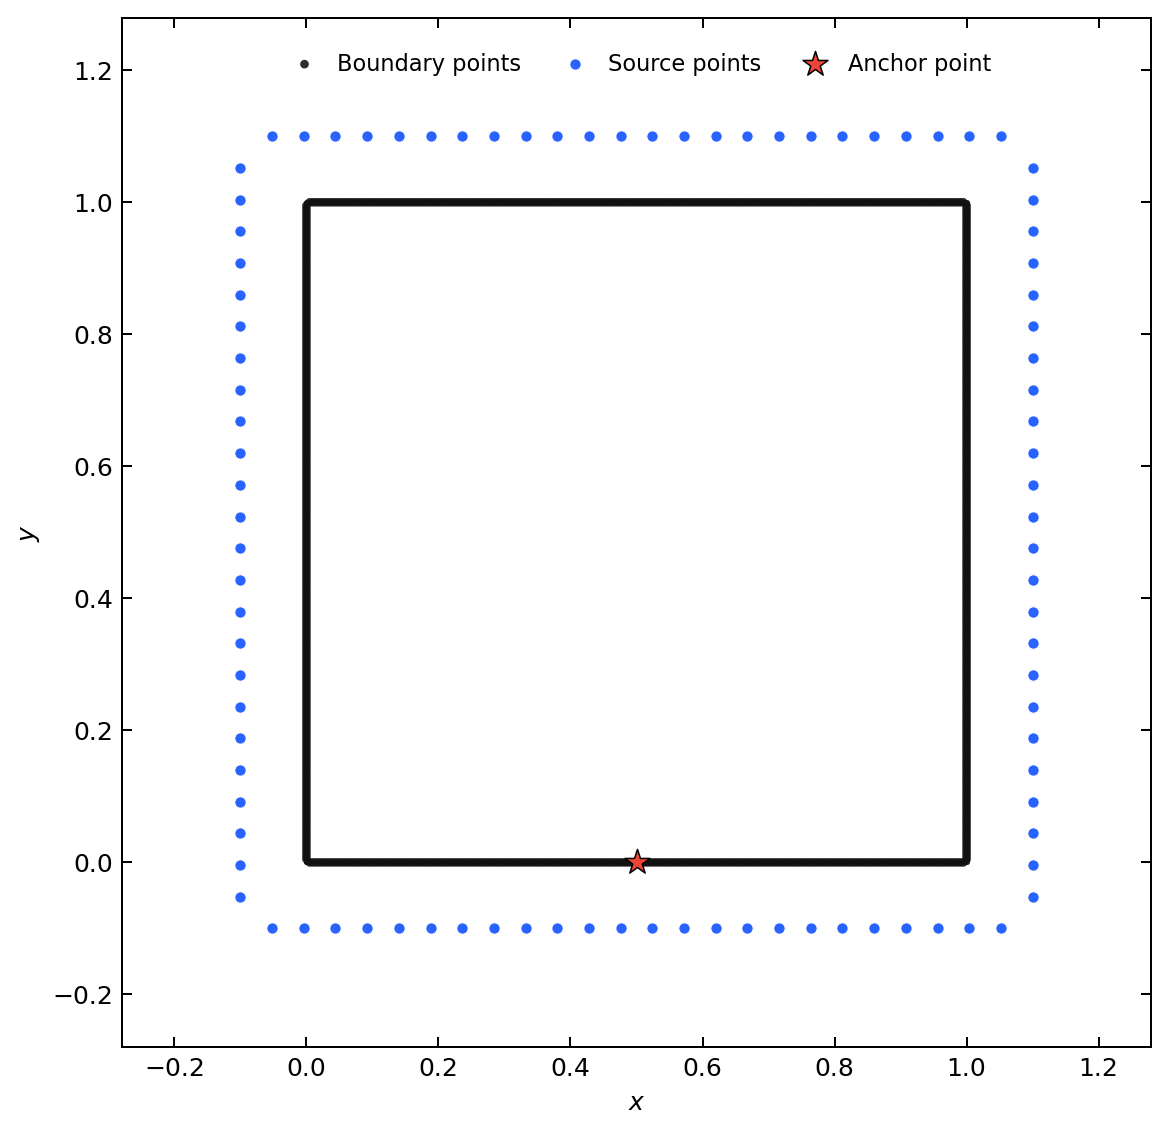

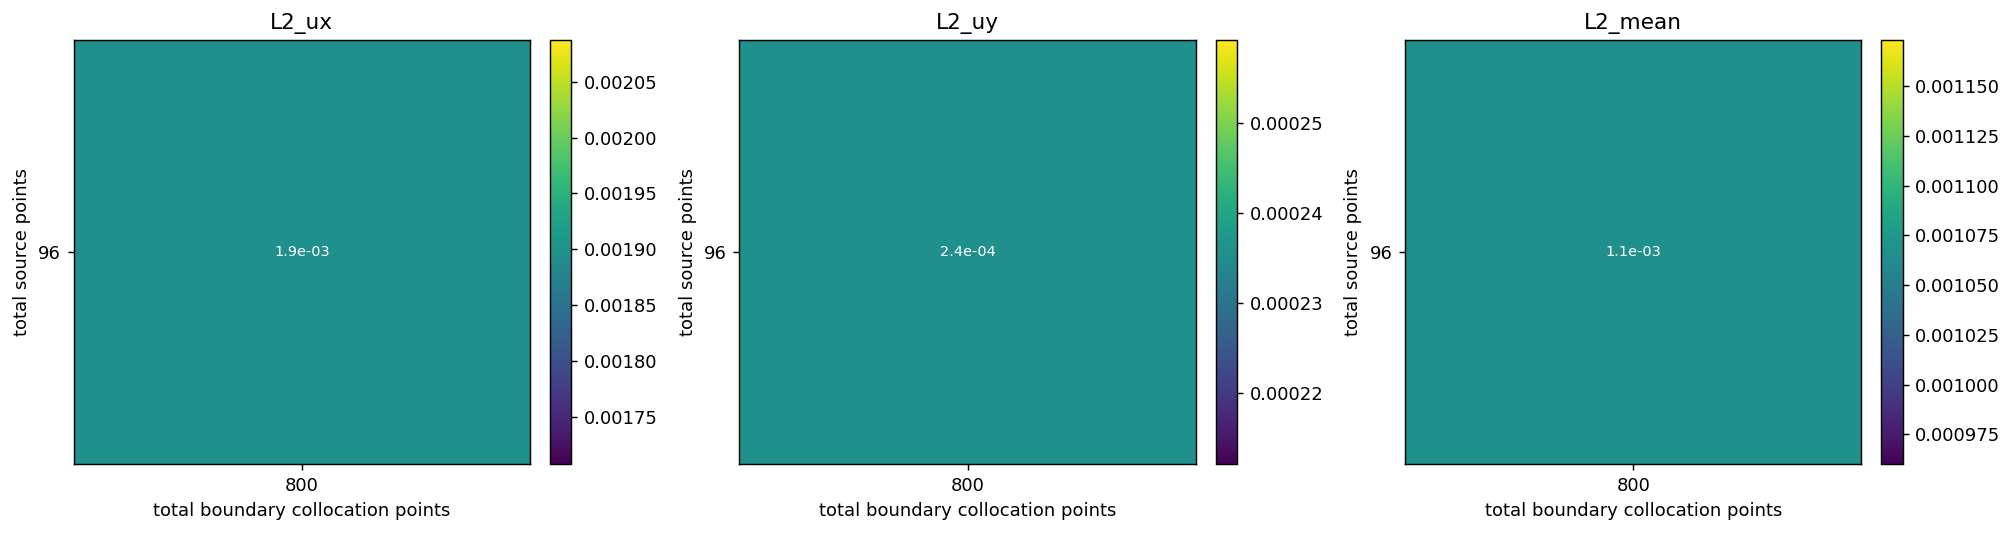

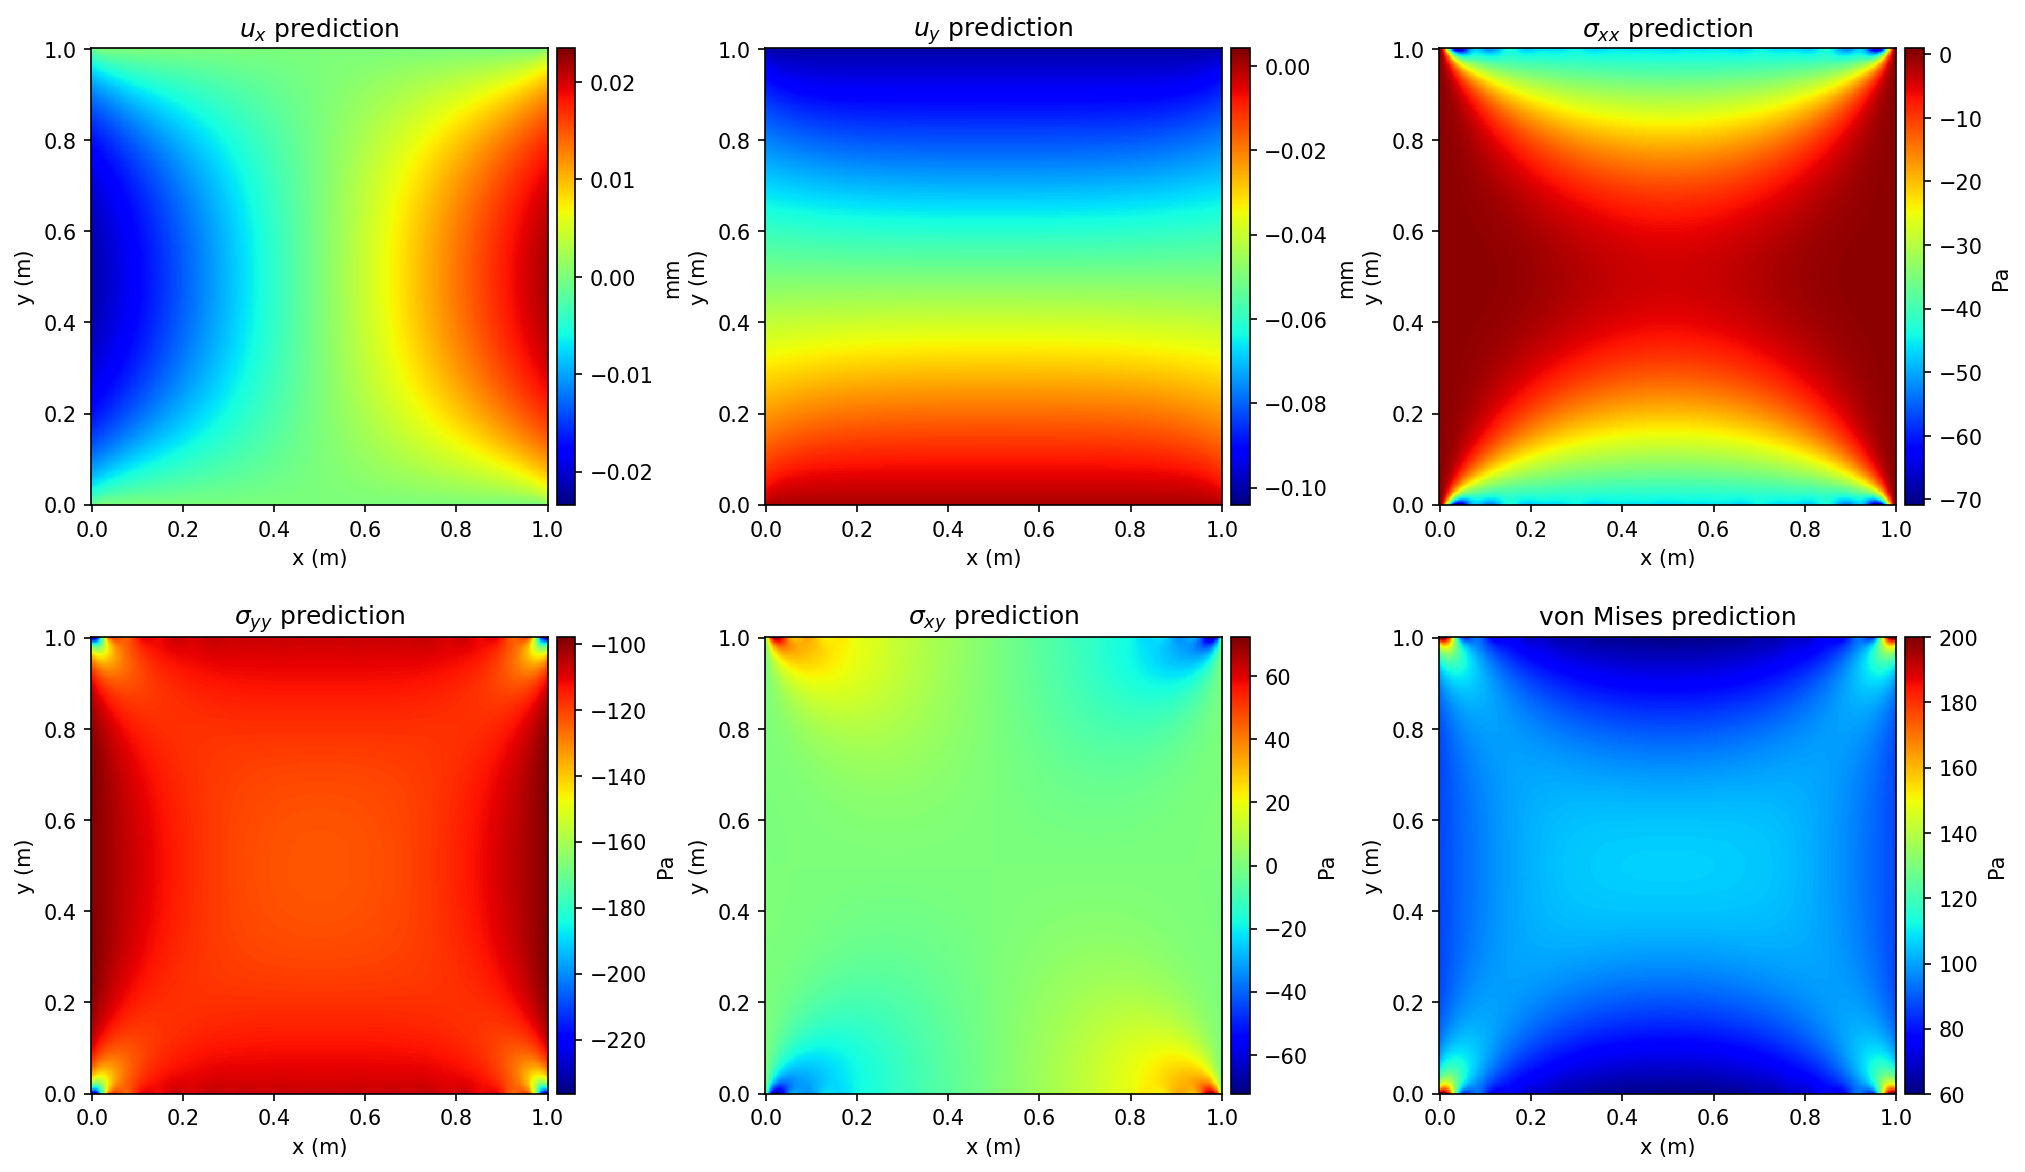

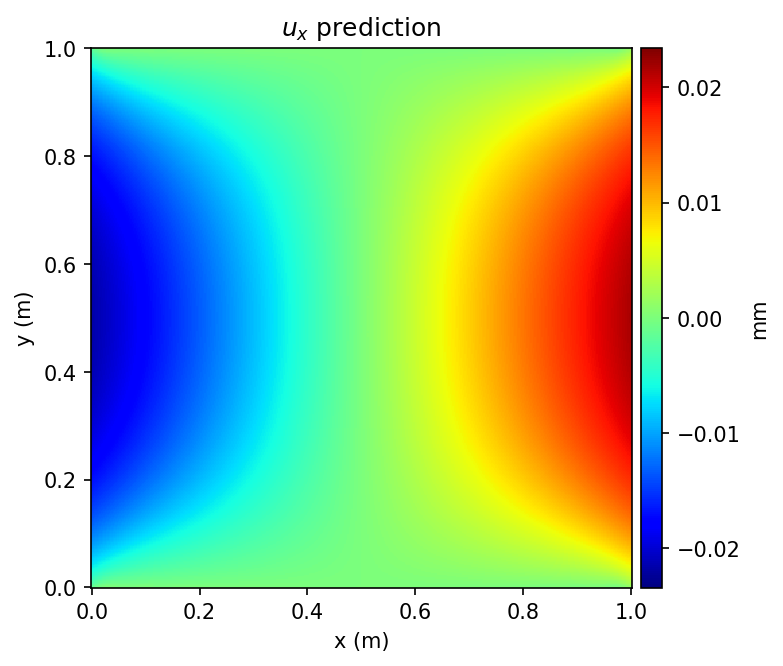

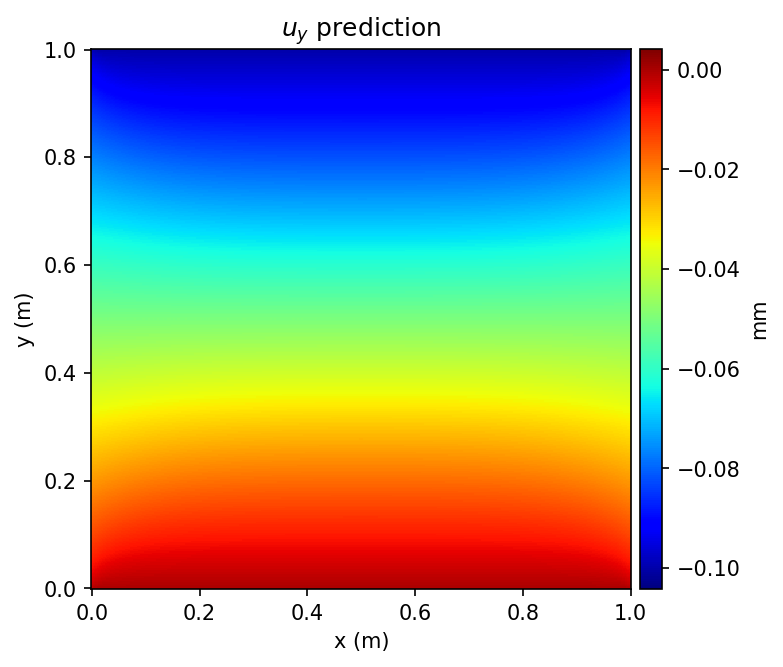

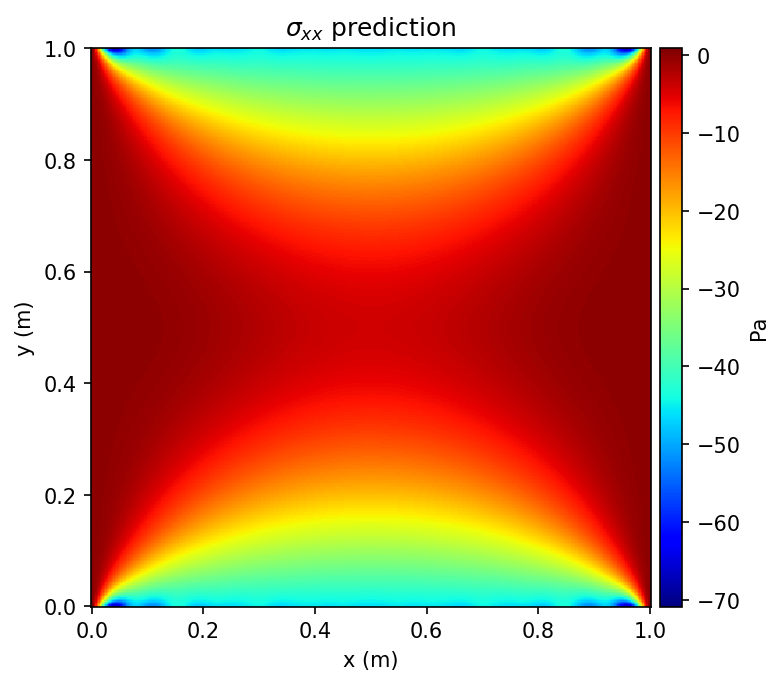

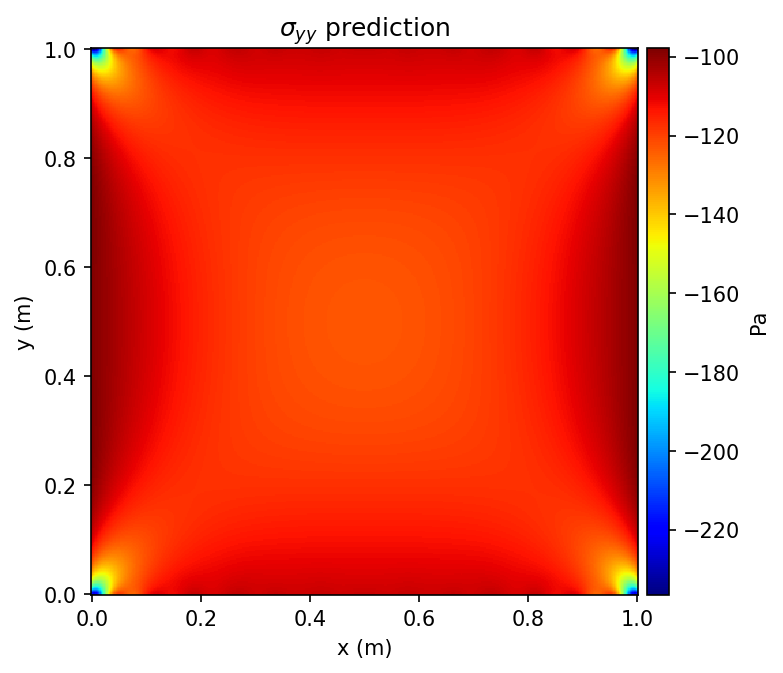

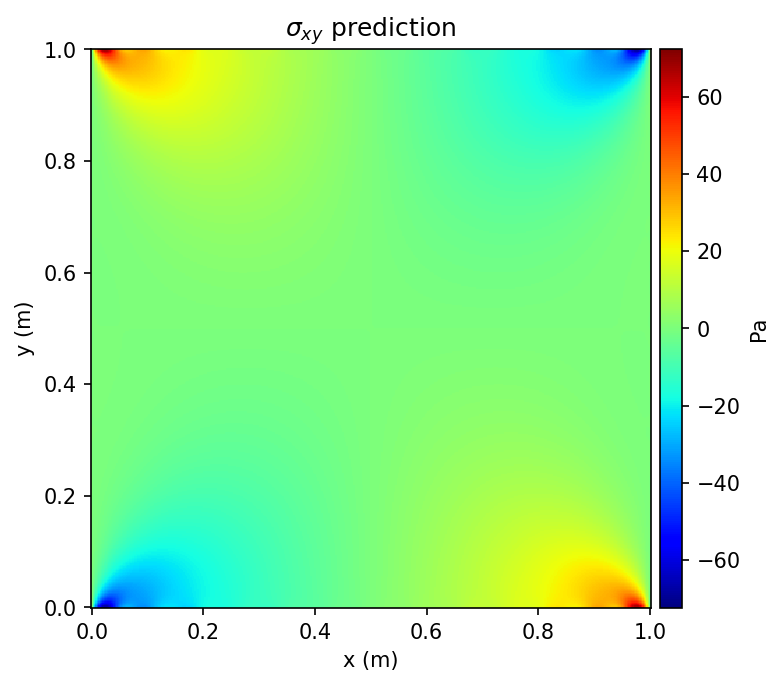

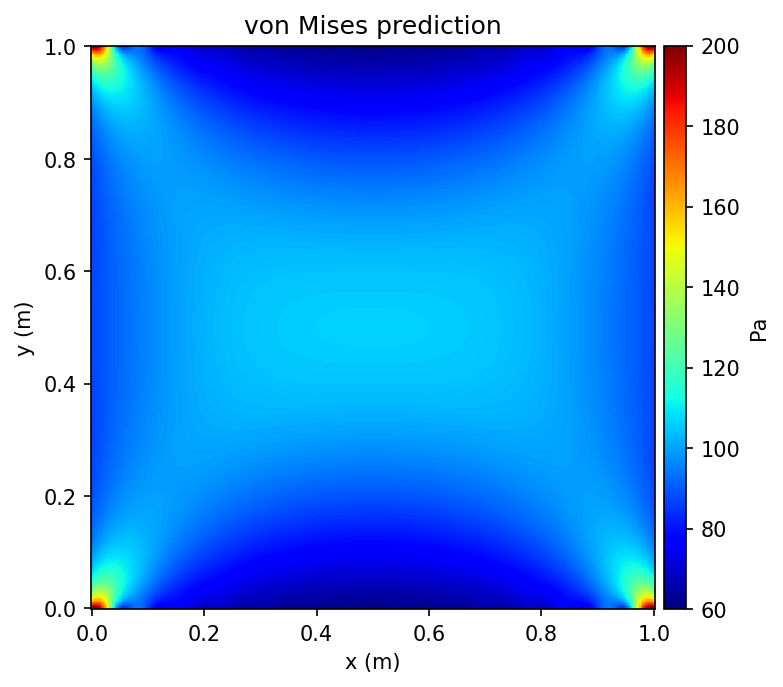

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
import random

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    from IPython.display import display
except ImportError:
    display = print

# ==========================================
# 0. 检查并设置运算设备 (CPU or CUDA)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前使用的计算设备: {device}")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# ==========================================
# 1. 物理参数与量纲归一化
# ==========================================
L = 1.0              # 正方形边长 (m)
E_real = 1.0e6       # 真实杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top_real = -1e-4# 顶边法向位移 (m)

scale_u = 1e4
E = 1.0
disp_top = disp_top_real * scale_u

kappa = 3.0 - 4.0 * nu
G = E / (2.0 * (1.0 + nu))

print(f"=== 单层基本解 CV-PINN 参数扫描 ===")
print(f"归一化参数: E* = {E}, 顶部施加位移 U* = {disp_top}")

# ==========================================
# 2. 源点/边界点生成与可视化
# ==========================================
def build_source_points(n_sources_per_side=24, source_offset=1.0):
    """生成外部相似正方形虚拟边界上的源点。

    source_offset 是真实方板每条边向外平移的距离。若用比例系数 alpha 控制，
    则 source_offset = 0.5 * (alpha - 1) * L。
    每条外部边取 n_sources_per_side 个源点，不包含角点。
    """
    offset = float(source_offset)
    cx, cy = 0.5 * L, 0.5 * L
    half_len = 0.5 * L + offset
    lo_x, hi_x = cx - half_len, cx + half_len
    lo_y, hi_y = cy - half_len, cy + half_len

    t_x = np.linspace(lo_x, hi_x, n_sources_per_side + 2, dtype=np.float32)[1:-1]
    t_y = np.linspace(lo_y, hi_y, n_sources_per_side + 2, dtype=np.float32)[1:-1]

    bottom = np.column_stack([t_x, np.full_like(t_x, lo_y)])
    right = np.column_stack([np.full_like(t_y, hi_x), t_y])
    top = np.column_stack([t_x[::-1], np.full_like(t_x, hi_y)])
    left = np.column_stack([np.full_like(t_y, lo_x), t_y[::-1]])
    return np.vstack([bottom, right, top, left]).astype(np.float32)

def build_boundary_points(n_bnd=200):
    """生成四条边界上的训练配点。n_bnd 表示每条边内部配点数，不包含角点。"""
    t = np.linspace(0.0, 1.0, n_bnd + 2, dtype=np.float32)[1:-1]
    bottom = np.column_stack([t, np.zeros_like(t)])
    top = np.column_stack([t, np.ones_like(t)])
    left = np.column_stack([np.zeros_like(t), t])
    right = np.column_stack([np.ones_like(t), t])
    return {
        "bottom": bottom,
        "top": top,
        "left": left,
        "right": right,
    }

def plot_source_boundary_points(n_sources_per_side=24, n_bnd=200, source_offset=1.0, ax=None):
    """?????????????????????"""
    src = build_source_points(n_sources_per_side, source_offset)
    bnd = build_boundary_points(n_bnd)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.8, 6.3), dpi=180)
    else:
        fig = ax.figure

    ax.set_facecolor('white')

    square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=float)
    ax.plot(
        square[:, 0], square[:, 1],
        color='#1f2937', linewidth=2.0, solid_capstyle='round', zorder=1,
    )

    bnd_all = np.vstack(list(bnd.values()))
    boundary_scatter = ax.scatter(
        bnd_all[:, 0], bnd_all[:, 1],
        s=12, c='#111111', alpha=0.88, marker='o',
        edgecolors='none', label='Boundary points', zorder=2,
    )

    src_scatter = ax.scatter(
        src[:, 0], src[:, 1],
        s=20, c='#1f5cff', alpha=0.96, marker='o',
        edgecolors='white', linewidths=0.35, label='Source points', zorder=3,
    )

    anchor = np.array([[0.5, 0.0]], dtype=float)
    anchor_scatter = ax.scatter(
        anchor[:, 0], anchor[:, 1],
        s=110, c='#f04438', marker='*',
        edgecolors='black', linewidths=0.6, label='Anchor point', zorder=5,
    )

    pad = source_offset + 0.18
    ax.set_xlim(-pad, 1.0 + pad)
    ax.set_ylim(-pad, 1.0 + pad)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(r'$x$', labelpad=4)
    ax.set_ylabel(r'$y$', labelpad=4)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, length=4, width=0.8)
    ax.minorticks_off()
    ax.legend(
        handles=[boundary_scatter, src_scatter, anchor_scatter],
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=3,
        frameon=True,
        fancybox=True,
        framealpha=0.92,
        facecolor='white',
        edgecolor='none',
        fontsize=9,
        handletextpad=0.45,
        columnspacing=1.4,
        borderpad=0.35,
    )
    ax.grid(False)
    fig.tight_layout(pad=0.75)
    return fig, ax

# ==========================================
# 3. 单层基本解复势网络 (实部/虚部显式实现)
# ==========================================
class CVNN(nn.Module):
    """KM 复势点力基本解网络。

    每个外部源点 zeta_j 只对应一个复点力 P_j=Fx_j+i*Fy_j。
    该点力同时耦合决定 Phi_j 和 Psi_j，避免原模型中 phi/psi
    两组独立权重破坏点力基本解的物理关系。
    """
    def __init__(self, n_sources_per_side=24, source_offset=0.35):
        super().__init__()
        source_pts = build_source_points(n_sources_per_side, source_offset)
        source_x = torch.tensor(source_pts[:, 0], dtype=torch.float32)
        source_y = torch.tensor(source_pts[:, 1], dtype=torch.float32)

        # 对数分支方向指向区域中心，避免源点外移后在物理域内出现分支跳变。
        theta = torch.atan2(0.5 - source_y, 0.5 - source_x)

        self.n_sources_per_side = int(n_sources_per_side)
        self.source_offset = float(source_offset)
        self.n_basis = int(source_x.numel())
        self.register_buffer("source_x", source_x.view(1, -1))
        self.register_buffer("source_y", source_y.view(1, -1))
        self.register_buffer("rot_cos", torch.cos(theta).view(1, -1))
        self.register_buffer("rot_sin", torch.sin(theta).view(1, -1))
        self.register_buffer("branch_angle", theta.view(1, -1))

        weight_scale = 1.0e-2 / np.sqrt(self.n_basis)
        # 每个源点只有一个复点力 P_j = P_re_j + i P_im_j。
        self.w_force_re = nn.Parameter(weight_scale * torch.randn(self.n_basis, 1))
        self.w_force_im = nn.Parameter(weight_scale * torch.randn(self.n_basis, 1))

        # 规则 KM 复势补充项，用于表示刚体位移、均匀应力等低阶场。
        # affine[0] 为常数项，affine[1] 为 z 的系数。
        self.affine_phi = nn.Parameter(torch.zeros(2, 2))
        self.affine_psi = nn.Parameter(torch.zeros(2, 2))

    @staticmethod
    def _add_affine(out_re, out_im, affine, x, y):
        c_re, c_im = affine[0, 0], affine[0, 1]
        a_re, a_im = affine[1, 0], affine[1, 1]
        out_re = out_re + c_re + a_re * x - a_im * y
        out_im = out_im + c_im + a_re * y + a_im * x
        return out_re, out_im

    def forward(self, x, y):
        x_col = x.reshape(-1, 1)
        y_col = y.reshape(-1, 1)
        dx = x_col - self.source_x
        dy = y_col - self.source_y

        # q_j = z - zeta_j，使用旋转后的对数分支保持物理区域内连续。
        q_re = dx
        q_im = dy
        w_re = self.rot_cos * q_re + self.rot_sin * q_im
        w_im = self.rot_cos * q_im - self.rot_sin * q_re

        scale = np.sqrt(self.n_basis)
        r2 = torch.clamp(q_re.square() + q_im.square(), min=1.0e-30)
        log_q_re = 0.5 * torch.log(r2) / scale
        # log(q) = log(exp(-i*theta)q) + i*theta。
        log_q_im = (torch.atan2(w_im, w_re) + self.branch_angle) / scale

        inv_r2 = 1.0 / r2
        inv_q_re = q_re * inv_r2 / scale
        inv_q_im = -q_im * inv_r2 / scale

        # 图示中的点力复势基本解：
        # Phi_j = -P_j/[2*pi*(kappa+1)] log(q_j)
        # Psi_j = [kappa*conj(P_j) log(q_j)
        #           + P_j*conj(zeta_j)/q_j]/[2*pi*(kappa+1)]
        cf = 1.0 / (2.0 * np.pi * (float(kappa) + 1.0))

        # P_j * log(q_j)
        p_log_re = log_q_re @ self.w_force_re - log_q_im @ self.w_force_im
        p_log_im = log_q_re @ self.w_force_im + log_q_im @ self.w_force_re
        phi_R = -cf * p_log_re
        phi_I = -cf * p_log_im

        # conj(P_j) * log(q_j)
        pbar_log_re = log_q_re @ self.w_force_re + log_q_im @ self.w_force_im
        pbar_log_im = -log_q_re @ self.w_force_im + log_q_im @ self.w_force_re

        # conj(zeta_j) / q_j
        zeta_bar_re = self.source_x
        zeta_bar_im = -self.source_y
        zeta_bar_over_q_re = zeta_bar_re * inv_q_re - zeta_bar_im * inv_q_im
        zeta_bar_over_q_im = zeta_bar_re * inv_q_im + zeta_bar_im * inv_q_re

        # P_j * conj(zeta_j)/q_j
        p_zeta_bar_over_q_re = (
            zeta_bar_over_q_re @ self.w_force_re
            - zeta_bar_over_q_im @ self.w_force_im
        )
        p_zeta_bar_over_q_im = (
            zeta_bar_over_q_re @ self.w_force_im
            + zeta_bar_over_q_im @ self.w_force_re
        )

        psi_R = cf * (float(kappa) * pbar_log_re + p_zeta_bar_over_q_re)
        psi_I = cf * (float(kappa) * pbar_log_im + p_zeta_bar_over_q_im)

        phi_R, phi_I = self._add_affine(phi_R, phi_I, self.affine_phi, x_col, y_col)
        psi_R, psi_I = self._add_affine(psi_R, psi_I, self.affine_psi, x_col, y_col)
        return phi_R.reshape_as(x), phi_I.reshape_as(x), psi_R.reshape_as(x), psi_I.reshape_as(x)

# ==========================================
# 4. Muskhelishvili 物理场与边界损失
# ==========================================
def get_phys_fields(model, x, y):
    phi_R, phi_I, psi_R, psi_I = model(x, y)

    dphi_dx_R = torch.autograd.grad(phi_R, x, grad_outputs=torch.ones_like(phi_R), create_graph=True)[0]
    dphi_dx_I = torch.autograd.grad(phi_I, x, grad_outputs=torch.ones_like(phi_I), create_graph=True)[0]
    dpsi_dx_R = torch.autograd.grad(psi_R, x, grad_outputs=torch.ones_like(psi_R), create_graph=True)[0]
    dpsi_dx_I = torch.autograd.grad(psi_I, x, grad_outputs=torch.ones_like(psi_I), create_graph=True)[0]

    d2phi_dx2_R = torch.autograd.grad(dphi_dx_R, x, grad_outputs=torch.ones_like(dphi_dx_R), create_graph=True)[0]
    d2phi_dx2_I = torch.autograd.grad(dphi_dx_I, x, grad_outputs=torch.ones_like(dphi_dx_I), create_graph=True)[0]

    kappa_f = float(kappa)
    G_f = float(G)

    # 2G(u_x + i u_y) = kappa*phi - z*conj(phi') - conj(psi)
    z_conj_dphi_R = x * dphi_dx_R + y * dphi_dx_I
    z_conj_dphi_I = y * dphi_dx_R - x * dphi_dx_I
    u_x = (kappa_f * phi_R - z_conj_dphi_R - psi_R) / (2.0 * G_f)
    u_y = (kappa_f * phi_I - z_conj_dphi_I + psi_I) / (2.0 * G_f)

    # sigma_xx + sigma_yy = 4 Re(phi')
    # sigma_yy - sigma_xx + 2i*sigma_xy = 2(conj(z)*phi'' + psi')
    sum_sig = 4.0 * dphi_dx_R
    diff_R = 2.0 * (x * d2phi_dx2_R + y * d2phi_dx2_I + dpsi_dx_R)
    diff_I = 2.0 * (x * d2phi_dx2_I - y * d2phi_dx2_R + dpsi_dx_I)

    sig_xx = (sum_sig - diff_R) / 2.0
    sig_yy = (sum_sig + diff_R) / 2.0
    sig_xy = diff_I / 2.0

    return u_x, u_y, sig_xx, sig_yy, sig_xy

def _edge_tensors(n_bnd):
    # 不取角点，避免角点处位移/力边界条件混合导致的局部不适定影响训练。
    t = torch.linspace(0.0, 1.0, n_bnd + 2, device=device, dtype=torch.float32)[1:-1].view(-1, 1)
    z = torch.zeros_like(t)
    o = torch.ones_like(t)
    return {
        "bottom": (t.clone().requires_grad_(True), z.clone().requires_grad_(True)),
        "top": (t.clone().requires_grad_(True), o.clone().requires_grad_(True)),
        "left": (z.clone().requires_grad_(True), t.clone().requires_grad_(True)),
        "right": (o.clone().requires_grad_(True), t.clone().requires_grad_(True)),
    }

def get_bnd_loss(model, n_bnd):
    edges = _edge_tensors(n_bnd)

    x_bot, y_bot = edges["bottom"]
    ux_bot, uy_bot, _, _, _ = get_phys_fields(model, x_bot, y_bot)
    loss_bot = torch.mean(ux_bot**2 + uy_bot**2)

    x_top, y_top = edges["top"]
    ux_top, uy_top, _, _, _ = get_phys_fields(model, x_top, y_top)
    loss_top = torch.mean(ux_top**2 + (uy_top - disp_top)**2)

    x_left, y_left = edges["left"]
    _, _, sig_xx_left, _, sig_xy_left = get_phys_fields(model, x_left, y_left)
    loss_left = torch.mean(sig_xx_left**2 + sig_xy_left**2)

    x_right, y_right = edges["right"]
    _, _, sig_xx_right, _, sig_xy_right = get_phys_fields(model, x_right, y_right)
    loss_right = torch.mean(sig_xx_right**2 + sig_xy_right**2)

    return loss_bot + loss_top + loss_left + loss_right 


# --- Least-squares warm start for KM-FSNet output coefficients ---
def _kmfs_as_complex(points):
    points = np.asarray(points, dtype=float)
    return points[:, 0] + 1j * points[:, 1]


def _kmfs_coefficient_count(n_basis):
    # 每个源点一个复点力 P_j，再加 phi/psi 的常数和一次项。
    return 2 * int(n_basis) + 8


def _kmfs_unpack_coeffs(coeffs, n_basis):
    coeffs = np.asarray(coeffs, dtype=float)
    n = int(n_basis)
    idx = 0
    point_force = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    phi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    phi1 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi1 = coeffs[idx] + 1j * coeffs[idx+1]
    return point_force, phi0, phi1, psi0, psi1


def _kmfs_prepare_cache(points, source_points):
    z = _kmfs_as_complex(points)
    src_c = _kmfs_as_complex(source_points)
    dz = z[:, None] - src_c[None, :]

    center = 0.5 + 0.5j
    branch_angle = np.angle(center - src_c)
    rotated = dz * np.exp(-1j * branch_angle[None, :])
    n_basis = len(src_c)
    scale = np.sqrt(n_basis)

    # 采用与 torch 前向计算一致的连续对数分支。
    basis = (
        np.log(np.abs(rotated))
        + 1j * (np.angle(rotated) + branch_angle[None, :])
    ) / scale
    d1 = (1.0 / dz) / scale
    d2 = (-1.0 / (dz * dz)) / scale
    zeta_bar = np.conj(src_c)
    return {
        "z": z,
        "basis": basis,
        "d1": d1,
        "d2": d2,
        "zeta_bar": zeta_bar,
        "n_basis": n_basis,
    }


def _kmfs_fields_from_coeffs(coeffs, cache):
    z = cache["z"]
    basis = cache["basis"]
    d1 = cache["d1"]
    d2 = cache["d2"]
    n_basis = cache["n_basis"]

    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, n_basis)
    cf = 1.0 / (2.0 * np.pi * (float(kappa) + 1.0))
    zeta_bar = cache["zeta_bar"]

    # Phi = -P/[2*pi*(kappa+1)] log(q)
    phi = -cf * (basis @ point_force) + phi0 + phi1 * z
    dphi = -cf * (d1 @ point_force) + phi1
    d2phi = -cf * (d2 @ point_force)

    # Psi = [kappa*conj(P) log(q) + P*conj(zeta)/q]
    #       /[2*pi*(kappa+1)]
    psi = cf * (
        float(kappa) * (basis @ np.conj(point_force))
        + (d1 * zeta_bar[None, :]) @ point_force
    ) + psi0 + psi1 * z
    dpsi = cf * (
        float(kappa) * (d1 @ np.conj(point_force))
        + (d2 * zeta_bar[None, :]) @ point_force
    ) + psi1

    disp_complex = (kappa * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G)
    ux = disp_complex.real
    uy = disp_complex.imag

    sum_sig = 4.0 * dphi.real
    diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    sig_xx = 0.5 * (sum_sig - diff.real)
    sig_yy = 0.5 * (sum_sig + diff.real)
    sig_xy = 0.5 * diff.imag
    return ux, uy, sig_xx, sig_yy, sig_xy


def _kmfs_boundary_residual_numpy(coeffs, boundary_caches):
    ux_b, uy_b, _, _, _ = _kmfs_fields_from_coeffs(coeffs, boundary_caches["bottom"])
    ux_t, uy_t, _, _, _ = _kmfs_fields_from_coeffs(coeffs, boundary_caches["top"])
    _, _, sxx_l, _, sxy_l = _kmfs_fields_from_coeffs(coeffs, boundary_caches["left"])
    _, _, sxx_r, _, sxy_r = _kmfs_fields_from_coeffs(coeffs, boundary_caches["right"])

    return np.concatenate([
        ux_b,
        uy_b,
        ux_t,
        uy_t - disp_top,
        sxx_l,
        sxy_l,
        sxx_r,
        sxy_r,
    ])


def solve_kmfsnet_output_layer_lstsq(n_sources_per_side, source_offset, n_bnd, rcond=None, progress=True):
    """Use linear least squares to warm-start KM-FSNet output coefficients."""
    t0 = time.time()
    source_points = build_source_points(n_sources_per_side, source_offset).astype(float)
    boundary_points = build_boundary_points(n_bnd)
    boundary_caches = {
        name: _kmfs_prepare_cache(points, source_points)
        for name, points in boundary_points.items()
    }

    n_unknown = _kmfs_coefficient_count(len(source_points))
    zero = np.zeros(n_unknown, dtype=float)
    r0 = _kmfs_boundary_residual_numpy(zero, boundary_caches)
    A = np.empty((r0.size, n_unknown), dtype=float)

    if progress:
        print(f"  KM-FSNet LS warm start assembly: rows={r0.size}, unknowns={n_unknown}")

    for k in range(n_unknown):
        e = np.zeros(n_unknown, dtype=float)
        e[k] = 1.0
        A[:, k] = _kmfs_boundary_residual_numpy(e, boundary_caches) - r0

    coeffs, residuals, rank, singular_values = np.linalg.lstsq(A, -r0, rcond=rcond)
    final_residual = _kmfs_boundary_residual_numpy(coeffs, boundary_caches)
    elapsed = time.time() - t0

    rms = float(np.sqrt(np.mean(final_residual**2)))
    max_abs = float(np.max(np.abs(final_residual)))
    cond_est = float(singular_values[0] / singular_values[-1]) if singular_values.size and singular_values[-1] > 0 else np.inf
    info = {
        "lstsq_rank": int(rank),
        "lstsq_boundary_rms": rms,
        "lstsq_boundary_max_abs": max_abs,
        "lstsq_condition_est": cond_est,
        "lstsq_solve_time_s": float(elapsed),
    }
    return coeffs, info


def load_kmfsnet_coeffs_into_model(model, coeffs):
    n = int(model.n_basis)
    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, n)
    with torch.no_grad():
        model.w_force_re.copy_(torch.as_tensor(point_force.real.reshape(-1, 1), dtype=torch.float32, device=device))
        model.w_force_im.copy_(torch.as_tensor(point_force.imag.reshape(-1, 1), dtype=torch.float32, device=device))
        model.affine_phi.copy_(torch.as_tensor([[phi0.real, phi0.imag], [phi1.real, phi1.imag]], dtype=torch.float32, device=device))
        model.affine_psi.copy_(torch.as_tensor([[psi0.real, psi0.imag], [psi1.real, psi1.imag]], dtype=torch.float32, device=device))

# ==========================================
# 5. 训练、预测、L2 误差与参数扫描
# ==========================================
def train_single_case(
    n_sources_per_side,
    n_bnd,
    source_offset=0.35,
    use_lstsq_init=True,
    lstsq_rcond=None,
    adam_epochs=300,
    lbfgs_max_iter=300,
    lr=5e-4,
    seed=42,
    verbose=True,
):
    seed_everything(seed)
    case_model = CVNN(n_sources_per_side=n_sources_per_side, source_offset=source_offset).to(device)

    t0 = time.time()
    lstsq_info = {}

    if use_lstsq_init:
        coeffs, lstsq_info = solve_kmfsnet_output_layer_lstsq(
            n_sources_per_side=n_sources_per_side,
            source_offset=source_offset,
            n_bnd=n_bnd,
            rcond=lstsq_rcond,
            progress=verbose,
        )
        load_kmfsnet_coeffs_into_model(case_model, coeffs)
        if verbose:
            print(
                "  KM-FSNet LS init | "
                f"rank={lstsq_info['lstsq_rank']} | "
                f"rms={lstsq_info['lstsq_boundary_rms']:.4e} | "
                f"max={lstsq_info['lstsq_boundary_max_abs']:.4e} | "
                f"cond~={lstsq_info['lstsq_condition_est']:.4e}"
            )

    last_loss = None
    if int(adam_epochs) > 0:
        if verbose:
            print(f"  KM-FSNet Adam fine-tune from LS init: epochs={adam_epochs}, lr={lr:.2e}")
        optimizer = torch.optim.Adam(case_model.parameters(), lr=lr)
        for epoch in range(int(adam_epochs)):
            optimizer.zero_grad()
            loss = get_bnd_loss(case_model, n_bnd)
            loss.backward()
            optimizer.step()
            last_loss = loss.item()
            if verbose and (epoch % max(1, adam_epochs // 5) == 0 or epoch == adam_epochs - 1):
                print(f"  Adam {epoch:5d}/{adam_epochs} | loss={last_loss:.4e}")

    if int(lbfgs_max_iter) > 0:
        if verbose:
            print(f"  KM-FSNet L-BFGS fine-tune from current state: max_iter={lbfgs_max_iter}")
        lbfgs_optimizer = torch.optim.LBFGS(
            case_model.parameters(),
            lr=1.0,
            max_iter=int(lbfgs_max_iter),
            max_eval=int(lbfgs_max_iter * 1.5) + 1,
            history_size=100,
            tolerance_grad=1e-9,
            tolerance_change=1e-11,
            line_search_fn="strong_wolfe",
        )

        iter_count = [0]
        def closure():
            lbfgs_optimizer.zero_grad()
            loss = get_bnd_loss(case_model, n_bnd)
            loss.backward()
            iter_count[0] += 1
            if verbose and iter_count[0] % max(1, lbfgs_max_iter // 5) == 0:
                print(f"  L-BFGS {iter_count[0]:5d} | loss={loss.item():.4e}")
            return loss

        lbfgs_optimizer.step(closure)

    final_loss = float(get_bnd_loss(case_model, n_bnd).detach().cpu().item())
    elapsed = time.time() - t0
    return case_model, final_loss, elapsed, lstsq_info

def predict_displacement(model, pts, batch_size=10000):
    model.eval()
    u_chunks, v_chunks = [], []
    n_pts = pts.shape[0]
    for start in range(0, n_pts, batch_size):
        end = min(start + batch_size, n_pts)
        batch = pts[start:end]
        x = torch.tensor(batch[:, 0:1], dtype=torch.float32, device=device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=torch.float32, device=device, requires_grad=True)
        u_pred, v_pred, _, _, _ = get_phys_fields(model, x, y)
        u_chunks.append(u_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        v_chunks.append(v_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        del x, y, u_pred, v_pred
    return np.concatenate(u_chunks), np.concatenate(v_chunks)

def evaluate_l2_error(model, eval_pts=None, ref_u=None, batch_size=10000):
    if eval_pts is None:
        eval_pts = internal_pts
    if ref_u is None:
        ref_u = u_int

    u_pred_real, v_pred_real = predict_displacement(model, eval_pts, batch_size=batch_size)
    u_ref = ref_u[:, 0]
    v_ref = ref_u[:, 1]

    l2_ux = np.linalg.norm(u_pred_real - u_ref, 2) / max(np.linalg.norm(u_ref, 2), 1e-15)
    l2_uy = np.linalg.norm(v_pred_real - v_ref, 2) / max(np.linalg.norm(v_ref, 2), 1e-15)
    return {
        "L2_ux": float(l2_ux),
        "L2_uy": float(l2_uy),
        "L2_mean": float(0.5 * (l2_ux + l2_uy)),
        "L2_max": float(max(l2_ux, l2_uy)),
    }

def make_results_table(results):
    columns = [
        "source_per_side", "source_total",
        "boundary_per_edge", "boundary_total",
        "L2_ux", "L2_uy", "L2_mean", "L2_max",
        "final_boundary_loss", "train_time_s",
    ]
    if pd is not None:
        return pd.DataFrame(results)[columns]
    return [{k: row[k] for k in columns} for row in results]

def print_results_table(results):
    header = (
        f"{'src/side':>8} {'src total':>9} {'bnd/edge':>9} {'bnd total':>9} "
        f"{'L2 ux':>12} {'L2 uy':>12} {'L2 mean':>12} {'loss':>12} {'time(s)':>9}"
    )
    print(header)
    print("-" * len(header))
    for row in results:
        print(
            f"{row['source_per_side']:8d} {row['source_total']:9d} "
            f"{row['boundary_per_edge']:9d} {row['boundary_total']:9d} "
            f"{row['L2_ux']:12.4e} {row['L2_uy']:12.4e} {row['L2_mean']:12.4e} "
            f"{row['final_boundary_loss']:12.4e} {row['train_time_s']:9.2f}"
        )

def plot_l2_sweep_heatmaps(results, metric_names=("L2_ux", "L2_uy", "L2_mean")):
    source_totals = sorted({row["source_total"] for row in results})
    boundary_totals = sorted({row["boundary_total"] for row in results})
    fig, axes = plt.subplots(1, len(metric_names), figsize=(5.2 * len(metric_names), 4.2), dpi=130)
    if len(metric_names) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metric_names):
        mat = np.full((len(source_totals), len(boundary_totals)), np.nan)
        for row in results:
            i = source_totals.index(row["source_total"])
            j = boundary_totals.index(row["boundary_total"])
            mat[i, j] = row[metric]

        im = ax.imshow(mat, origin="lower", cmap="viridis", aspect="auto")
        ax.set_xticks(np.arange(len(boundary_totals)))
        ax.set_xticklabels(boundary_totals)
        ax.set_yticks(np.arange(len(source_totals)))
        ax.set_yticklabels(source_totals)
        ax.set_xlabel("total boundary collocation points")
        ax.set_ylabel("total source points")
        ax.set_title(metric)
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if np.isfinite(mat[i, j]):
                    ax.text(j, i, f"{mat[i, j]:.1e}", ha="center", va="center",
                            color="white", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    return fig, axes


def predict_physical_fields(model, pts, batch_size=10000):
    """预测 KM-FSNet 的六个物理量，并转换为真实量纲。"""
    model.eval()
    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []

    n_pts = pts.shape[0]
    for start in range(0, n_pts, batch_size):
        end = min(start + batch_size, n_pts)
        batch = pts[start:end]

        x = torch.tensor(batch[:, 0:1], dtype=torch.float32, device=device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=torch.float32, device=device, requires_grad=True)

        ux, uy, sig_xx, sig_yy, sig_xy = get_phys_fields(model, x, y)

        ux_chunks.append((ux.detach().cpu().numpy().reshape(-1)) / scale_u)
        uy_chunks.append((uy.detach().cpu().numpy().reshape(-1)) / scale_u)

        stress_scale = E_real / scale_u
        sxx_chunks.append((sig_xx.detach().cpu().numpy().reshape(-1)) * stress_scale)
        syy_chunks.append((sig_yy.detach().cpu().numpy().reshape(-1)) * stress_scale)
        sxy_chunks.append((sig_xy.detach().cpu().numpy().reshape(-1)) * stress_scale)

        del x, y, ux, uy, sig_xx, sig_yy, sig_xy
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sxx_real = np.concatenate(sxx_chunks)
    syy_real = np.concatenate(syy_chunks)
    sxy_real = np.concatenate(sxy_chunks)

    # 平面应变：sigma_zz = nu * (sigma_xx + sigma_yy)
    szz_real = nu * (sxx_real + syy_real)
    mises_real = np.sqrt(
        0.5 * ((sxx_real - syy_real)**2 +
               (syy_real - szz_real)**2 +
               (szz_real - sxx_real)**2) +
        3.0 * sxy_real**2
    )

    return {
        "ux": ux_real,
        "uy": uy_real,
        "sxx": sxx_real,
        "syy": syy_real,
        "sxy": sxy_real,
        "von_mises": mises_real,
    }

def make_regular_prediction_grid(n_grid=401):
    """生成用于绘制预测云图的规则网格。"""
    xs = np.linspace(0.0, L, int(n_grid), dtype=np.float32)
    ys = np.linspace(0.0, L, int(n_grid), dtype=np.float32)
    XX, YY = np.meshgrid(xs, ys, indexing="xy")
    pts = np.column_stack([XX.ravel(), YY.ravel()]).astype(np.float32)
    return xs, ys, XX, YY, pts

def _add_equal_height_colorbar(fig, ax, im, label):
    """让 colorbar 和云图坐标轴高度一致。"""
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def plot_kmfsnet_prediction_clouds(
    model,
    grid_n=401,
    batch_size=10000,
    out_dir="kmfsnet_prediction_clouds",
    save_fig=True,
    show=True,
    plot_limits=None,
):
    """绘制 KM-FSNet 的 ux, uy, sigma_xx, sigma_yy, sigma_xy, von Mises 六张预测云图。"""
    from pathlib import Path

    xs, ys, XX, YY, pred_pts = make_regular_prediction_grid(grid_n)
    fields = predict_physical_fields(model, pred_pts, batch_size=batch_size)
    plot_limits = dict(globals().get("BEM_PLOT_LIMITS", {})) if plot_limits is None else dict(plot_limits)

    def _field_limits(name, values):
        if name in plot_limits and plot_limits[name] is not None:
            lo, hi = plot_limits[name]
            return float(lo), float(hi)
        lo = float(np.min(values))
        hi = float(np.max(values))
        if np.isclose(lo, hi):
            span = max(abs(lo), abs(hi), 1.0)
            lo -= 0.05 * span
            hi += 0.05 * span
        return lo, hi

    plot_items = [
        ("ux", fields["ux"] * 1e3, r"$u_x$ prediction", "mm", "ux"),
        ("uy", fields["uy"] * 1e3, r"$u_y$ prediction", "mm", "uy"),
        ("sxx", fields["sxx"], r"$\sigma_{xx}$ prediction", "Pa", "sxx"),
        ("syy", fields["syy"], r"$\sigma_{yy}$ prediction", "Pa", "syy"),
        ("sxy", fields["sxy"], r"$\sigma_{xy}$ prediction", "Pa", "sxy"),
        ("von_mises", fields["von_mises"], "von Mises prediction", "Pa", "von_mises"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, (_, values, title, unit, limit_key) in zip(axes.ravel(), plot_items):
        grid_values = values.reshape(grid_n, grid_n)
        vmin, vmax = _field_limits(limit_key, values)
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet", vmin=vmin, vmax=vmax)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, unit)

    fig.tight_layout()

    single_paths = []
    if save_fig:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        combined_path = out_path / "kmfsnet_prediction_6_clouds.png"
        fig.savefig(combined_path, dpi=300, bbox_inches="tight")

        for name, values, title, unit, limit_key in plot_items:
            single_fig, single_ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
            grid_values = values.reshape(grid_n, grid_n)
            vmin, vmax = _field_limits(limit_key, values)
            im = single_ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet", vmin=vmin, vmax=vmax)
            single_ax.set_aspect("equal", adjustable="box")
            single_ax.set_xlabel("x (m)")
            single_ax.set_ylabel("y (m)")
            single_ax.set_title(title)
            _add_equal_height_colorbar(single_fig, single_ax, im, unit)
            single_fig.tight_layout()

            save_path = out_path / f"kmfsnet_prediction_{name}.png"
            single_fig.savefig(save_path, dpi=300, bbox_inches="tight")
            single_paths.append(save_path)
            if not show:
                plt.close(single_fig)

        print(f"KM-FSNet 预测云图已保存: {combined_path}")
        for save_path in single_paths:
            print(f"  {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    fields["x_grid"] = XX
    fields["y_grid"] = YY
    fields["points"] = pred_pts
    return fields, fig

def run_source_boundary_sweep(
    source_counts_per_side,
    boundary_counts_per_edge,
    source_offset=0.35,
    use_lstsq_init=True,
    lstsq_rcond=None,
    adam_epochs=300,
    lbfgs_max_iter=300,
    lr=5e-4,
    seed=42,
    verbose=True,
):
    if "internal_pts" not in globals() or "u_int" not in globals():
        raise RuntimeError("请先运行 notebook 的 BEM 参考解单元，确保 internal_pts 和 u_int 已经存在。")

    results = []
    best_model = None
    best_result = None
    total_cases = len(source_counts_per_side) * len(boundary_counts_per_edge)
    case_id = 0

    for n_src in source_counts_per_side:
        for n_bnd in boundary_counts_per_edge:
            case_id += 1
            print(f"\n[{case_id}/{total_cases}] source_per_side={n_src}, boundary_per_edge={n_bnd}")
            case_model, final_loss, elapsed, lstsq_info = train_single_case(
                n_sources_per_side=n_src,
                n_bnd=n_bnd,
                source_offset=source_offset,
                use_lstsq_init=use_lstsq_init,
                lstsq_rcond=lstsq_rcond,
                adam_epochs=adam_epochs,
                lbfgs_max_iter=lbfgs_max_iter,
                lr=lr,
                seed=seed + case_id,
                verbose=verbose,
            )
            metrics = evaluate_l2_error(case_model, internal_pts, u_int)
            row = {
                "source_per_side": int(n_src),
                "source_total": int(4 * n_src),
                "boundary_per_edge": int(n_bnd),
                "boundary_total": int(4 * n_bnd),
                "final_boundary_loss": float(final_loss),
                "train_time_s": float(elapsed),
                "use_lstsq_init": bool(use_lstsq_init),
                "adam_epochs": int(adam_epochs),
                "lbfgs_max_iter": int(lbfgs_max_iter),
                **lstsq_info,
                **metrics,
            }
            results.append(row)
            print(
                f"  L2_ux={row['L2_ux']:.4e}, L2_uy={row['L2_uy']:.4e}, "
                f"L2_mean={row['L2_mean']:.4e}, loss={final_loss:.4e}, time={elapsed:.2f}s"
            )

            if best_result is None or row["L2_mean"] < best_result["L2_mean"]:
                if best_model is not None:
                    del best_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                best_model = case_model
                best_result = row.copy()
            else:
                del case_model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    return results, best_model, best_result

# ==========================================
# 6. 参数扫描配置与运行
# ==========================================
# n_sources_per_side 是外部相似正方形每条边上的源点数；总源点数 = 4 * n_sources_per_side。
SWEEP_SOURCE_COUNTS_PER_SIDE = [ 24]
# n_bnd 是每条物理边界上的训练配点数；总边界训练点数 = 4 * n_bnd。
SWEEP_BOUNDARY_COUNTS_PER_EDGE = [ 200]
SOURCE_SCALE = 1.2  # 外部源点正方形相对真实方板的边长比例 alpha
SOURCE_OFFSET = 0.5 * (SOURCE_SCALE - 1.0) * L

# 快速探索可先用 500/200；正式对比建议增大到 2000/1000 或更高。
USE_LSTSQ_INIT = True
LSTSQ_RCOND = None
ADAM_EPOCHS = 300
LBFGS_MAX_ITER = 300
LEARNING_RATE = 5e-4
RUN_SWEEP = True
PLOT_KMFSNET_PREDICTION = True
KMFSNET_PRED_GRID_N = 401
KMFSNET_PRED_BATCH_SIZE = 10000
KMFSNET_PRED_OUT_DIR = "kmfsnet_prediction_clouds"

# 先画一张默认组合下的源点/边界配点分布图。
plot_source_boundary_points(
    n_sources_per_side=SWEEP_SOURCE_COUNTS_PER_SIDE[-1],
    n_bnd=SWEEP_BOUNDARY_COUNTS_PER_EDGE[-1],
    source_offset=SOURCE_OFFSET,
)

if RUN_SWEEP:
    sweep_results, best_model, best_result = run_source_boundary_sweep(
        SWEEP_SOURCE_COUNTS_PER_SIDE,
        SWEEP_BOUNDARY_COUNTS_PER_EDGE,
        source_offset=SOURCE_OFFSET,
        use_lstsq_init=USE_LSTSQ_INIT,
        lstsq_rcond=LSTSQ_RCOND,
        adam_epochs=ADAM_EPOCHS,
        lbfgs_max_iter=LBFGS_MAX_ITER,
        lr=LEARNING_RATE,
        seed=42,
        verbose=True,
    )

    print("\n=== 不同源点数量与边界训练点数量对应的 L2 相对误差 ===")
    print_results_table(sweep_results)

    sweep_table = make_results_table(sweep_results)
    display(sweep_table)

    print("\n=== 当前最优组合（按 L2_mean） ===")
    print(best_result)

    model = best_model
    plot_l2_sweep_heatmaps(sweep_results)

    if PLOT_KMFSNET_PREDICTION:
        kmfsnet_prediction_fields, kmfsnet_prediction_fig = plot_kmfsnet_prediction_clouds(
            model,
            grid_n=KMFSNET_PRED_GRID_N,
            batch_size=KMFSNET_PRED_BATCH_SIZE,
            out_dir=KMFSNET_PRED_OUT_DIR,
            save_fig=True,
            show=True,
        )
else:
    model = CVNN(n_sources_per_side=24, source_offset=SOURCE_OFFSET).to(device)
    print("RUN_SWEEP=False，仅定义函数和默认 model，未运行参数扫描。")


KM-FSNet误差分析


参数扫描结果汇总与当前 model 的详细误差分析...

不同源点/边界配点组合的 L2 相对误差表:


,source_per_side,source_total,boundary_per_edge,boundary_total,L2_ux,L2_uy,L2_mean,L2_max,final_boundary_loss,train_time_s
0,24,96,200,800,0.001898,0.000236,0.001067,0.001898,0.000004,8.124204



当前用于详细误差图的最优组合:
{'source_per_side': 24, 'source_total': 96, 'boundary_per_edge': 200, 'boundary_total': 800, 'final_boundary_loss': 3.94703329220647e-06, 'train_time_s': 8.124204158782959, 'use_lstsq_init': True, 'adam_epochs': 300, 'lbfgs_max_iter': 300, 'lstsq_rank': 198, 'lstsq_boundary_rms': 0.0007026700563295488, 'lstsq_boundary_max_abs': 0.008025261742886869, 'lstsq_condition_est': 8213103963961965.0, 'lstsq_solve_time_s': 0.39072370529174805, 'L2_ux': 0.0018976153212277621, 'L2_uy': 0.00023571073505388224, 'L2_mean': 0.0010666630281408222, 'L2_max': 0.0018976153212277621}
--------------------------------------------------
Relative L2 error Ux: 1.898e-03
Relative L2 error Uy: 2.357e-04
Max Normalized Error Ux: 6.869e-03
Max Normalized Error Uy: 1.311e-03
--------------------------------------------------
--------------------------------------------------
Relative L2 error Ux: 1.898e-03
Relative L2 error Uy: 2.357e-04
Relative L2 error Von Mises: 2.099e-03
Max Normalized Error Ux

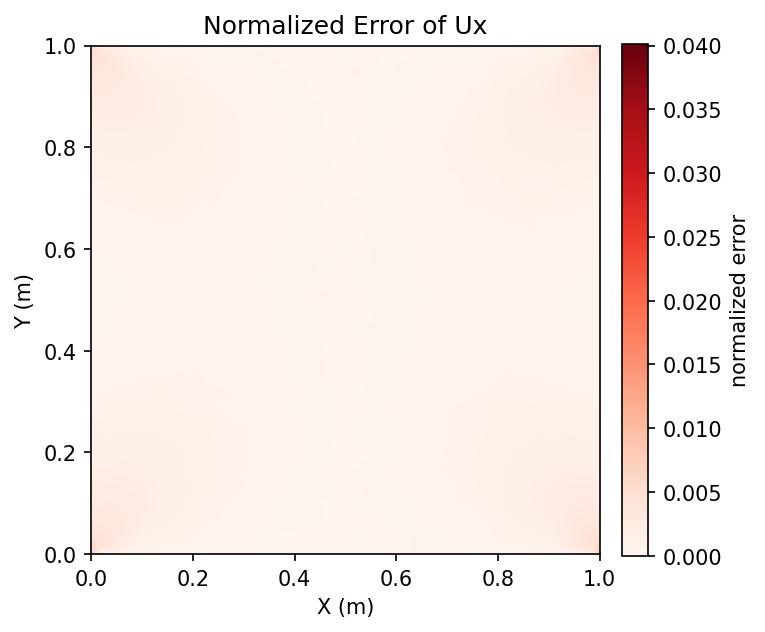

saved: kmfsnet_bem_error_clouds\normalized_error_ux.png


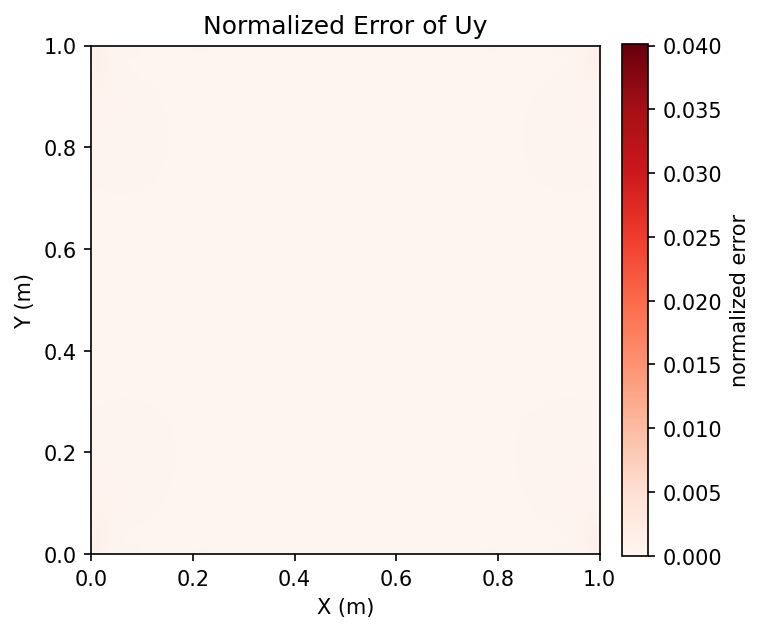

saved: kmfsnet_bem_error_clouds\normalized_error_uy.png


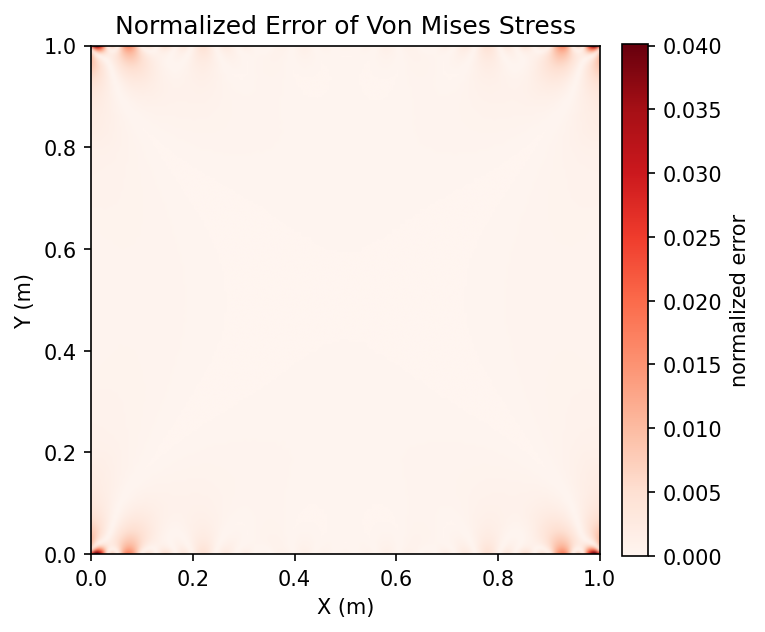

saved: kmfsnet_bem_error_clouds\normalized_error_von_mises.png


In [6]:
# 8. 参数扫描结果汇总与当前 model 的详细误差分布
# ==========================================
print("\n参数扫描结果汇总与当前 model 的详细误差分析...")

if "sweep_table" in globals():
    print("\n不同源点/边界配点组合的 L2 相对误差表:")
    display(sweep_table)

if "best_result" in globals():
    print("\n当前用于详细误差图的最优组合:")
    print(best_result)

# 使用 BEM 的内部网格点作为参考解点
u_pred_bem_real, v_pred_bem_real = predict_displacement(model, internal_pts, batch_size=10000)

u_bem_ref = u_int[:, 0]
v_bem_ref = u_int[:, 1]

norm_factor_ux = max(np.max(np.abs(u_bem_ref)), 1e-15)
norm_factor_uy = max(np.max(np.abs(v_bem_ref)), 1e-15)

err_ux_norm = np.abs(u_pred_bem_real - u_bem_ref) / norm_factor_ux
err_uy_norm = np.abs(v_pred_bem_real - v_bem_ref) / norm_factor_uy

L2_ux = np.linalg.norm(u_pred_bem_real - u_bem_ref, 2) / max(np.linalg.norm(u_bem_ref, 2), 1e-15)
L2_uy = np.linalg.norm(v_pred_bem_real - v_bem_ref, 2) / max(np.linalg.norm(v_bem_ref, 2), 1e-15)

print("-" * 50)
print(f"Relative L2 error Ux: {L2_ux:.3e}")
print(f"Relative L2 error Uy: {L2_uy:.3e}")
print(f"Max Normalized Error Ux: {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy: {err_uy_norm.max():.3e}")
print("-" * 50)

n_side = int(np.sqrt(internal_pts.shape[0]))
extent = [0, L, 0, L]

from pathlib import Path

# 误差比较必须在 BEM 的 internal_pts 上重新预测，不能复用 401x401 云图数据。
pred_fields = predict_physical_fields(model, internal_pts, batch_size=10000)
if len(pred_fields["ux"]) != len(internal_pts):
    raise ValueError("KM-FSNet 与 BEM 误差比较时，预测点数和参考点数不一致。")

u_pred_bem_real = pred_fields["ux"]
v_pred_bem_real = pred_fields["uy"]
vm_pred_bem_real = pred_fields["von_mises"]

u_bem_ref = u_int[:, 0]
v_bem_ref = u_int[:, 1]
vm_bem_ref = von_mises

norm_factor_ux = max(np.max(np.abs(u_bem_ref)), 1e-15)
norm_factor_uy = max(np.max(np.abs(v_bem_ref)), 1e-15)
norm_factor_vm = max(np.max(np.abs(vm_bem_ref)), 1e-15)

err_ux_norm = np.abs(u_pred_bem_real - u_bem_ref) / norm_factor_ux
err_uy_norm = np.abs(v_pred_bem_real - v_bem_ref) / norm_factor_uy
err_vm_norm = np.abs(vm_pred_bem_real - vm_bem_ref) / norm_factor_vm

L2_ux = np.linalg.norm(u_pred_bem_real - u_bem_ref, 2) / max(np.linalg.norm(u_bem_ref, 2), 1e-15)
L2_uy = np.linalg.norm(v_pred_bem_real - v_bem_ref, 2) / max(np.linalg.norm(v_bem_ref, 2), 1e-15)
L2_vm = np.linalg.norm(vm_pred_bem_real - vm_bem_ref, 2) / max(np.linalg.norm(vm_bem_ref, 2), 1e-15)

print("-" * 50)
print(f"Relative L2 error Ux: {L2_ux:.3e}")
print(f"Relative L2 error Uy: {L2_uy:.3e}")
print(f"Relative L2 error Von Mises: {L2_vm:.3e}")
print(f"Max Normalized Error Ux: {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy: {err_uy_norm.max():.3e}")
print(f"Max Normalized Error Von Mises: {err_vm_norm.max():.3e}")
print("-" * 50)

err_vmax = max(float(err_ux_norm.max()), float(err_uy_norm.max()), float(err_vm_norm.max()))
error_out_dir = Path("kmfsnet_bem_error_clouds")
error_out_dir.mkdir(parents=True, exist_ok=True)

def _plot_single_normalized_error(values, title, filename):
    fig, ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
    im = ax.imshow(
        values.reshape(n_side, n_side),
        origin="lower",
        extent=extent,
        cmap="Reds",
        aspect="equal",
        interpolation="bicubic",
        vmin=0.0,
        vmax=err_vmax,
    )
    ax.set_title(title)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("normalized error")
    fig.tight_layout()
    save_path = error_out_dir / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"saved: {save_path}")

_plot_single_normalized_error(err_ux_norm, "Normalized Error of Ux", "normalized_error_ux.png")
_plot_single_normalized_error(err_uy_norm, "Normalized Error of Uy", "normalized_error_uy.png")
_plot_single_normalized_error(err_vm_norm, "Normalized Error of Von Mises Stress", "normalized_error_von_mises.png")


PINN的误差分析

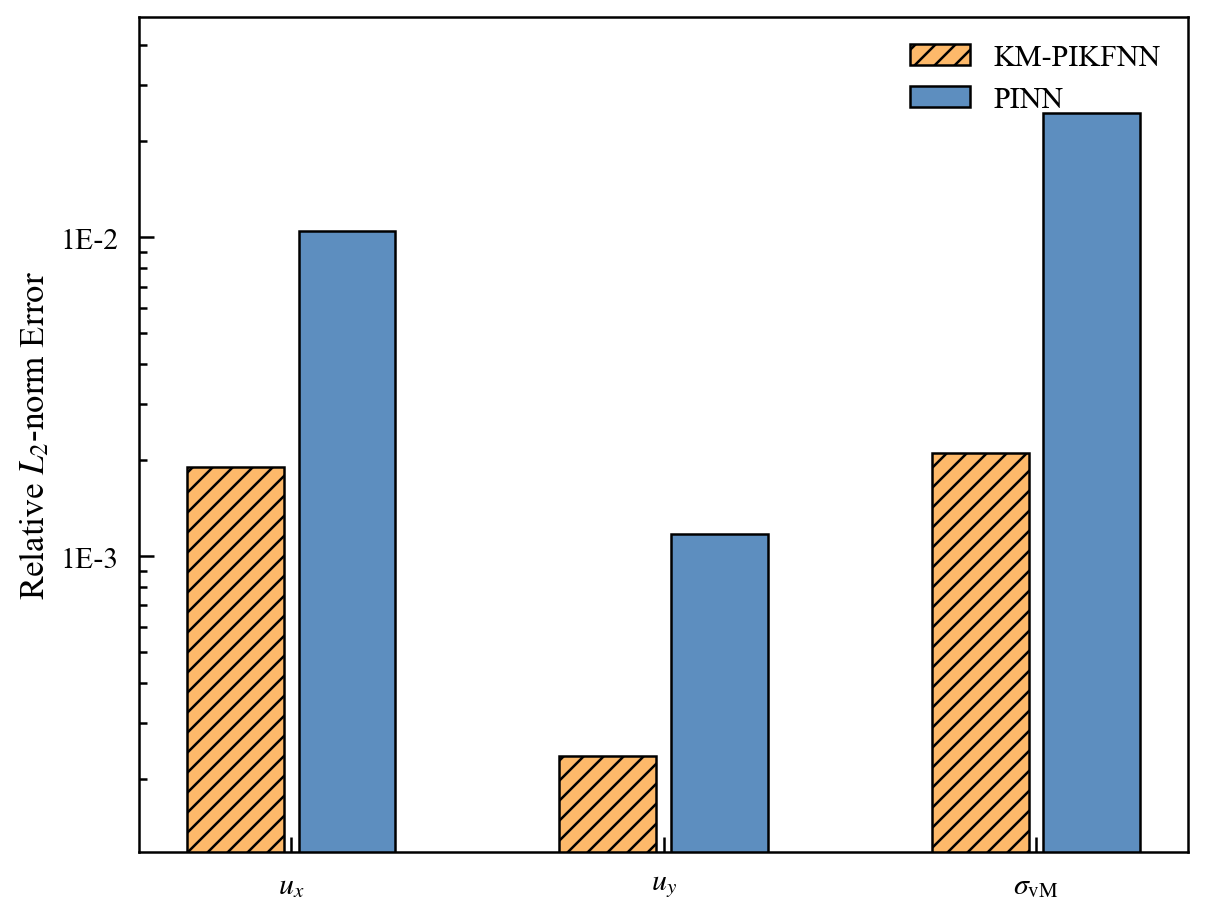

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import LogLocator, FuncFormatter

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'


labels = [
    r'$u_x$',
    r'$u_y$',
    r'$\sigma_{\mathrm{vM}}$'
]

km_pikfnn_errors = [
    1.898e-03,
    2.357e-04,
    2.099e-03
]

pinn_errors = [
    1.0446e-02,
    1.1753e-03,
    2.4552e-02
]

x = np.arange(len(labels))
width = 0.26
gap = 0.04

fig, ax = plt.subplots(figsize=(6.8, 5.2), dpi=180)

rects1 = ax.bar(
    x - width / 2 - gap / 2,
    km_pikfnn_errors,
    width,
    label='KM-PIKFNN',
    color='#FDB96A',
    edgecolor='black',
    linewidth=1.0,
    hatch='///'
)

rects2 = ax.bar(
    x + width / 2 + gap / 2,
    pinn_errors,
    width,
    label='PINN',
    color='#5D8EBF',
    edgecolor='black',
    linewidth=1.0
)

ax.set_yscale('log')

all_errors = np.asarray(km_pikfnn_errors + pinn_errors)
ax.set_ylim(
    max(1e-5, np.min(all_errors) * 0.5),
    np.max(all_errors) * 2.0
)

ax.set_ylabel(r'Relative $L_2$-norm Error', fontsize=14)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=15)

def log_formatter(val, pos):
    if val >= 0.1:
        return "0.1"
    exponent = int(np.log10(val))
    return f"1E{exponent}"

ax.yaxis.set_major_formatter(FuncFormatter(log_formatter))
ax.yaxis.set_minor_locator(
    LogLocator(
        base=10.0,
        subs=np.arange(2, 10) * 0.1,
        numticks=100
    )
)

ax.tick_params(
    axis='both',
    which='major',
    direction='in',
    length=6,
    width=1,
    labelsize=12,
    pad=8
)

ax.tick_params(
    axis='y',
    which='minor',
    direction='in',
    length=3,
    width=1
)

ax.legend(
    loc='upper right',
    frameon=False,
    fontsize=12
)

ax.spines['top'].set_linewidth(1.0)
ax.spines['right'].set_linewidth(1.0)
ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)

plt.tight_layout()

plt.savefig(
    "error_comparison_with_von_mises.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Fig. 4：KM-FSNet 与 COMSOL 参考解的六物理量误差云图

读取 COMSOL 导出的六物理量参考解，使用当前训练好的 KM-FSNet 模型在同一坐标点上预测，并绘制 `u_x, u_y, sigma_xx, sigma_yy, sigma_xy, von Mises` 的误差云图。

Fig. 4 KM-FSNet 误差总图已保存: kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_6_clouds_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_ux_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_uy_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_sxx_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_syy_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_sxy_absolute.png
  kmfsnet_comsol_error_clouds\fig4_kmfsnet_comsol_error_von_mises_absolute.png

=== KM-FSNet vs COMSOL 六物理量相对 L2 误差 ===
L2_ux: 2.6482e-03
L2_uy: 3.6509e-04
L2_sxx: 6.9505e-02
L2_syy: 9.6791e-03
L2_sxy: 1.0014e-01
L2_von_mises: 1.4488e-02


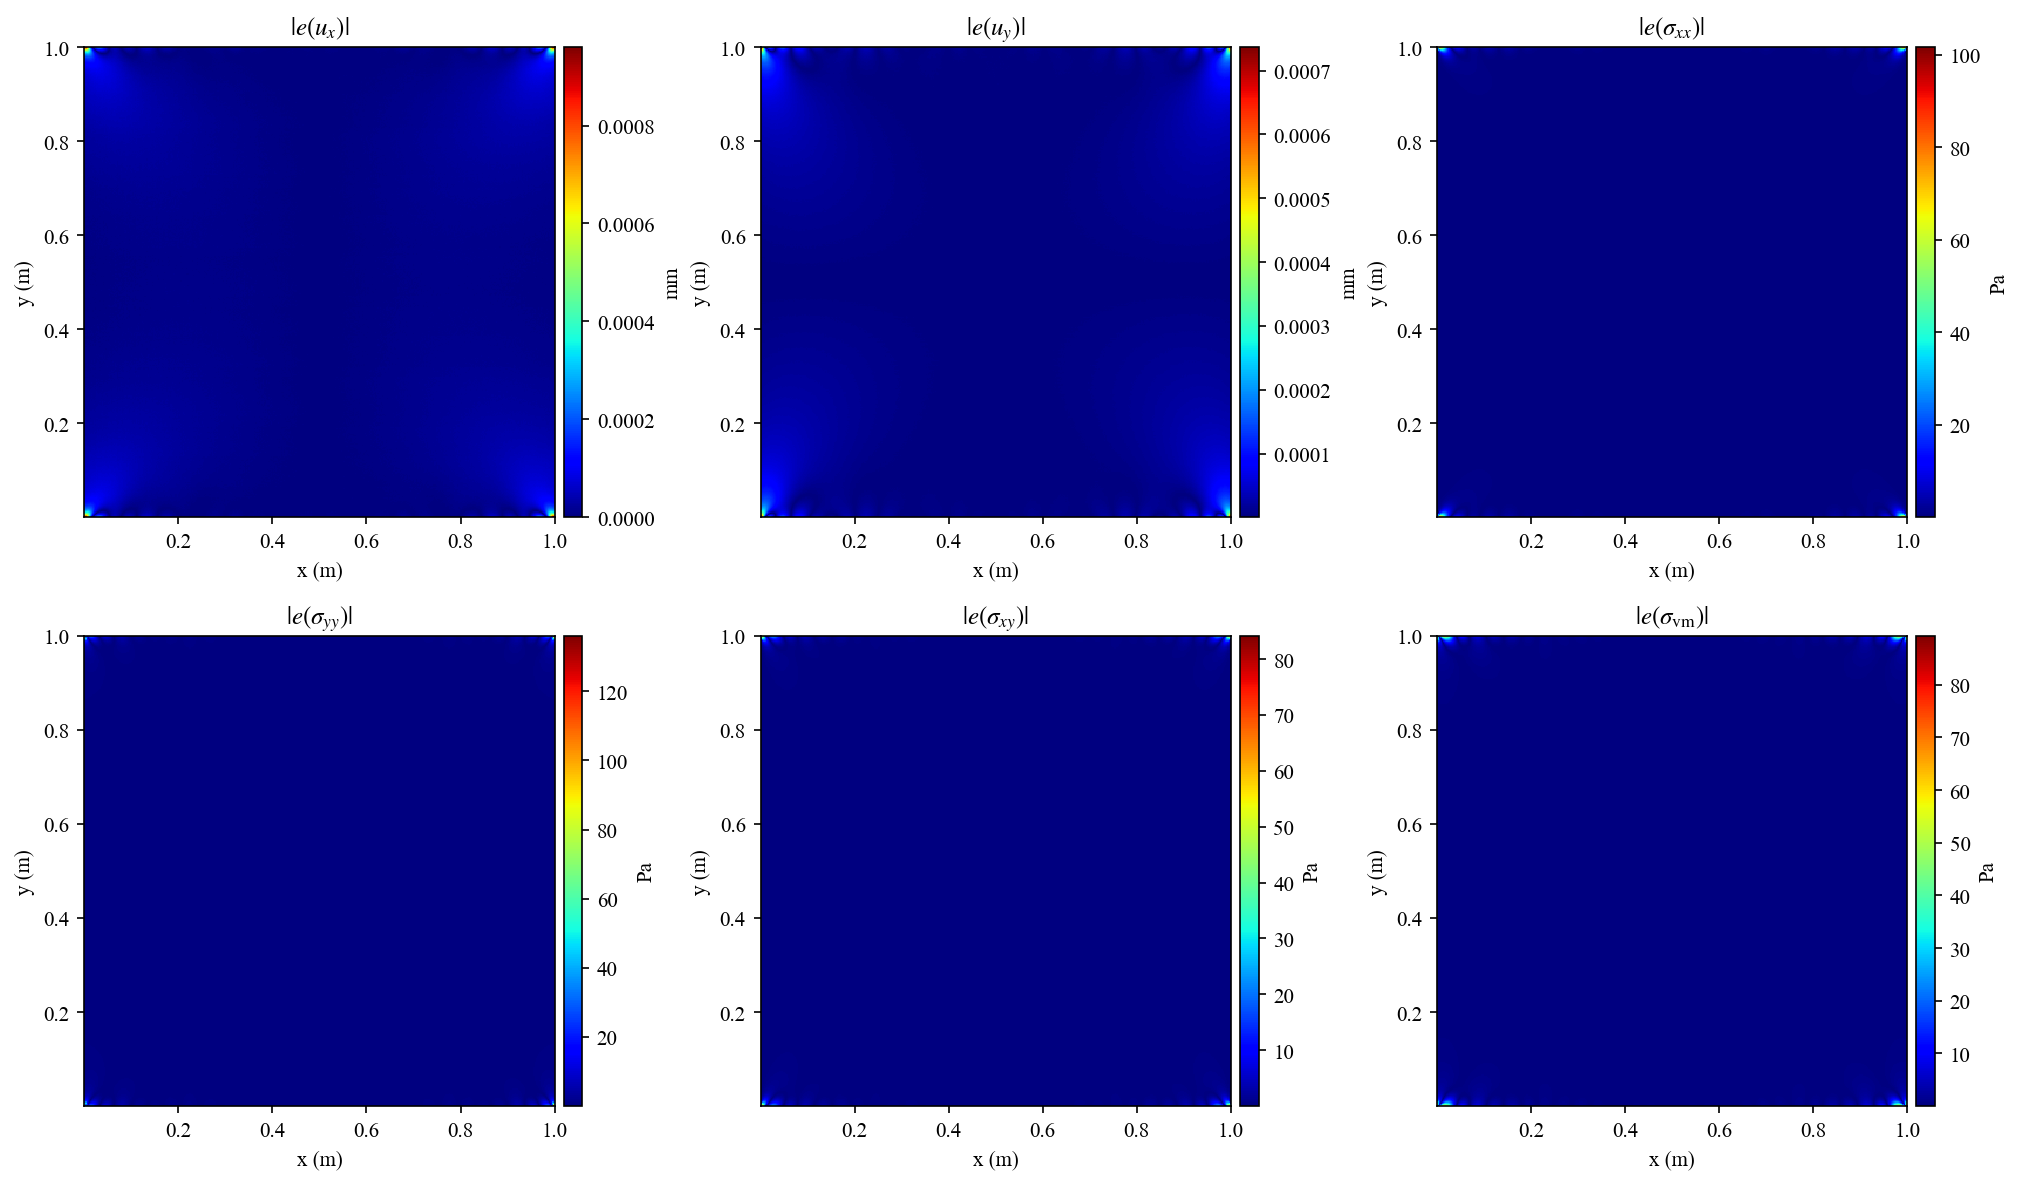

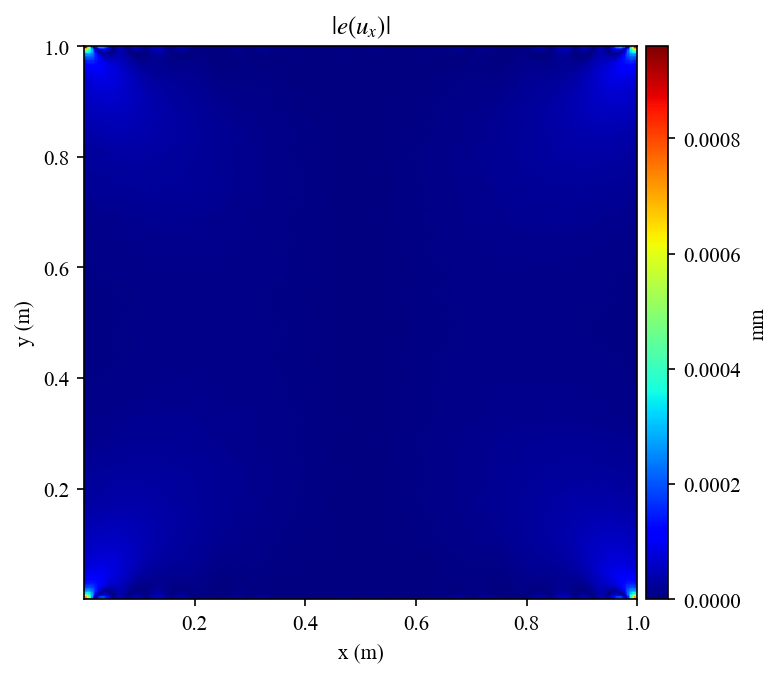

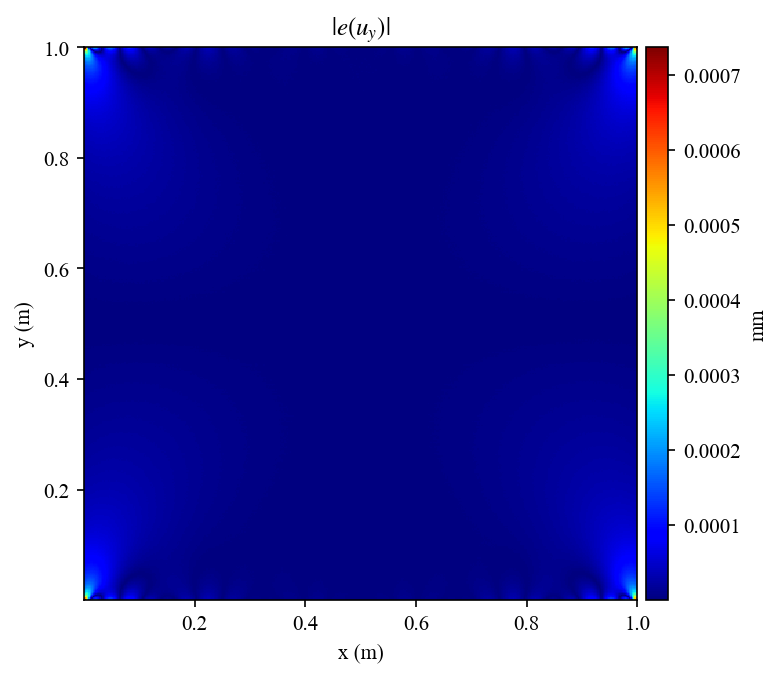

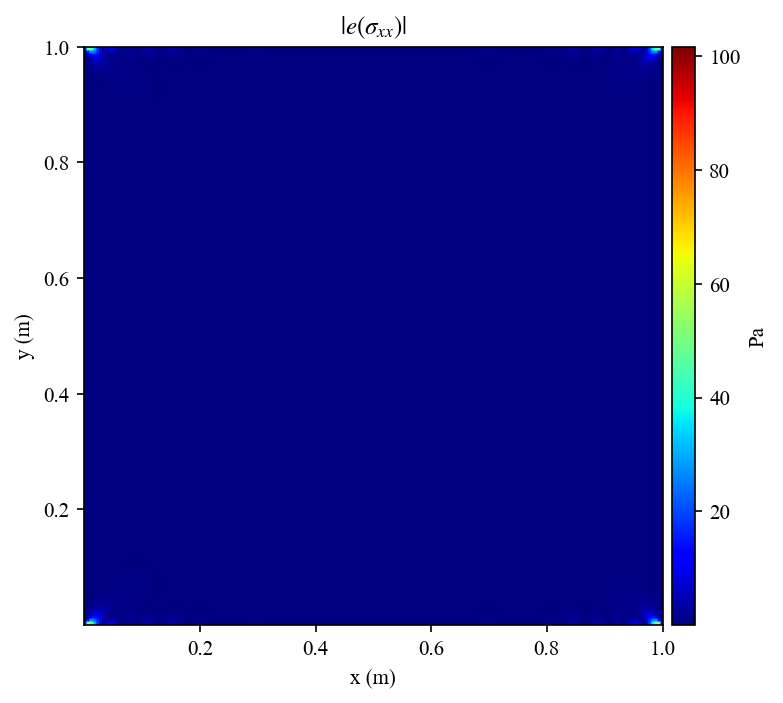

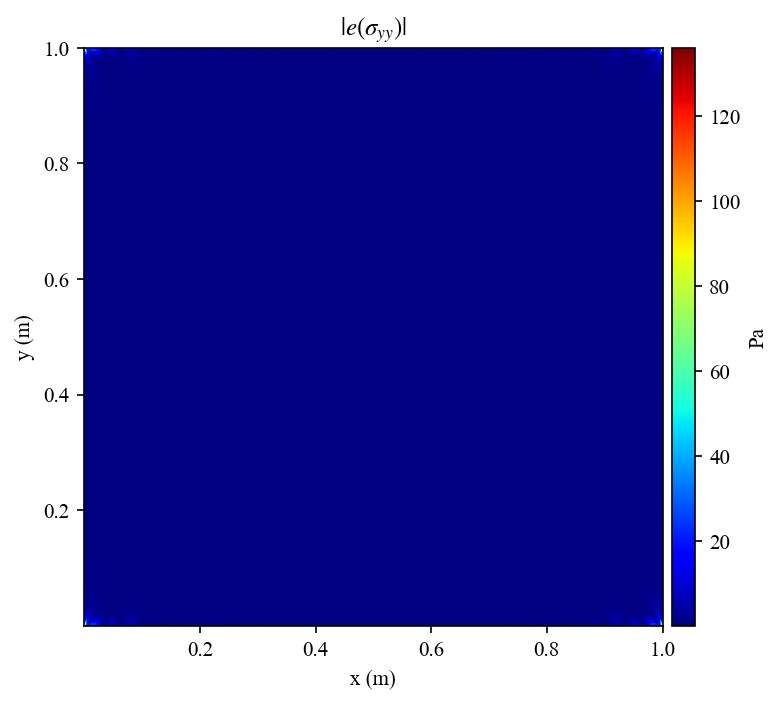

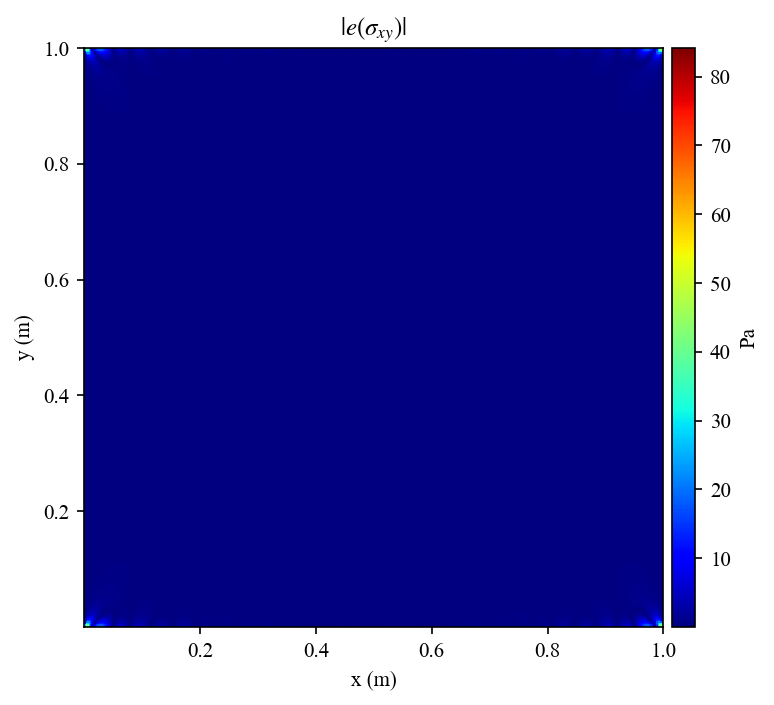

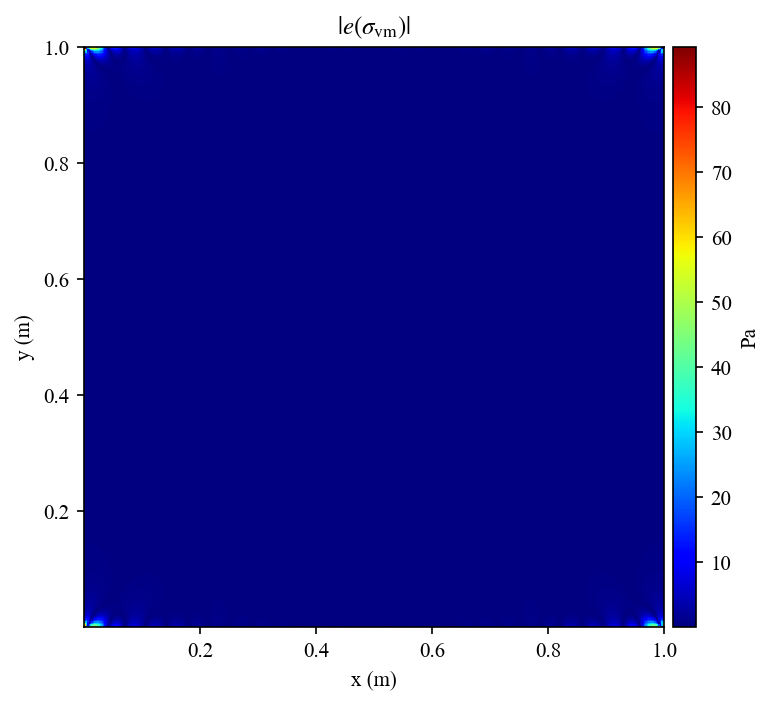

In [9]:
# ==========================================
# Fig. 4：KM-FSNet 与 COMSOL 参考解的六物理量误差云图
# ==========================================
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

COMSOL_REF_PATH = Path(r"C:\Users\magic\Desktop\KM-PIKFNN\方板受压\方板受压comsol.txt")
KMFSNET_ERROR_OUT_DIR = Path("kmfsnet_comsol_error_clouds")

def load_comsol_reference_table(txt_path=COMSOL_REF_PATH):
    """读取 COMSOL 电子表格 txt：X, Y, u, v, sx, sy, sxy, mises。"""
    txt_path = Path(txt_path)
    if not txt_path.exists():
        raise FileNotFoundError(f"找不到 COMSOL 参考解文件: {txt_path}")

    data = np.loadtxt(txt_path, comments="%")
    if data.ndim != 2 or data.shape[1] < 8:
        raise ValueError(f"COMSOL 文件至少需要 8 列，当前 shape={data.shape}")

    return {
        "points": data[:, 0:2].astype(np.float32),
        "x": data[:, 0],
        "y": data[:, 1],
        "ux": data[:, 2],
        "uy": data[:, 3],
        "sxx": data[:, 4],
        "syy": data[:, 5],
        "sxy": data[:, 6],
        "von_mises": data[:, 7],
        "raw": data,
    }

def regular_grid_from_points(points, values, decimals=12):
    """把规则网格散点整理成 pcolormesh 可用的 xs, ys, values_grid。"""
    points = np.asarray(points, dtype=float)
    values = np.asarray(values, dtype=float).reshape(-1)
    xr = np.round(points[:, 0], decimals)
    yr = np.round(points[:, 1], decimals)
    xs = np.unique(xr)
    ys = np.unique(yr)

    if xs.size * ys.size != values.size:
        raise ValueError(
            f"COMSOL 点不是规则网格: nx={xs.size}, ny={ys.size}, n={values.size}"
        )

    grid = np.full((ys.size, xs.size), np.nan, dtype=float)
    ix = np.searchsorted(xs, xr)
    iy = np.searchsorted(ys, yr)
    grid[iy, ix] = values
    if np.isnan(grid).any():
        raise ValueError("规则网格存在缺失点，请检查 COMSOL 导出数据。")
    return xs, ys, grid

def _add_equal_height_colorbar(fig, ax, im, label):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def relative_l2(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return float(np.linalg.norm(pred - ref, 2) / max(np.linalg.norm(ref, 2), 1e-15))

def plot_kmfsnet_comsol_error_clouds(
    model,
    comsol_path=COMSOL_REF_PATH,
    batch_size=10000,
    out_dir=KMFSNET_ERROR_OUT_DIR,
    error_mode="absolute",
    save_fig=True,
    show=True,
):
    """绘制 KM-FSNet 相对于 COMSOL 参考解的六物理量误差云图。

    error_mode:
        "absolute"：绝对误差，位移单位 mm，应力单位 Pa。
        "normalized"：按每个参考场的 max(abs(ref)) 归一化误差。
    """
    ref = load_comsol_reference_table(comsol_path)
    pts = ref["points"]

    pred = predict_physical_fields(model, pts, batch_size=batch_size)

    fields = [
        ("ux", pred["ux"] * 1e3, ref["ux"] * 1e3, r"$|e(u_x)|$", "mm"),
        ("uy", pred["uy"] * 1e3, ref["uy"] * 1e3, r"$|e(u_y)|$", "mm"),
        ("sxx", pred["sxx"], ref["sxx"], r"$|e(\sigma_{xx})|$", "Pa"),
        ("syy", pred["syy"], ref["syy"], r"$|e(\sigma_{yy})|$", "Pa"),
        ("sxy", pred["sxy"], ref["sxy"], r"$|e(\sigma_{xy})|$", "Pa"),
        ("von_mises", pred["von_mises"], ref["von_mises"], r"$|e(\sigma_{\mathrm{vm}})|$", "Pa"),
    ]

    plot_items = []
    metrics = {}
    for name, pred_values, ref_values, title, unit in fields:
        abs_err = np.abs(pred_values - ref_values)
        if error_mode == "normalized":
            values = abs_err / max(np.max(np.abs(ref_values)), 1e-15)
            plot_unit = "normalized"
            plot_title = title + " / max|ref|"
        elif error_mode == "absolute":
            values = abs_err
            plot_unit = unit
            plot_title = title
        else:
            raise ValueError("error_mode 只能是 'absolute' 或 'normalized'")

        plot_items.append((name, values, plot_title, plot_unit))
        metrics[f"L2_{name}"] = relative_l2(pred_values, ref_values)
        metrics[f"max_abs_error_{name}"] = float(np.max(abs_err))

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, (_, values, title, unit) in zip(axes.ravel(), plot_items):
        xs, ys, grid_values = regular_grid_from_points(pts, values)
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, unit)

    fig.tight_layout()

    single_paths = []
    if save_fig:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        combined_path = out_path / f"fig4_kmfsnet_comsol_error_6_clouds_{error_mode}.png"
        fig.savefig(combined_path, dpi=300, bbox_inches="tight")

        for name, values, title, unit in plot_items:
            single_fig, single_ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
            xs, ys, grid_values = regular_grid_from_points(pts, values)
            im = single_ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
            single_ax.set_aspect("equal", adjustable="box")
            single_ax.set_xlabel("x (m)")
            single_ax.set_ylabel("y (m)")
            single_ax.set_title(title)
            _add_equal_height_colorbar(single_fig, single_ax, im, unit)
            single_fig.tight_layout()

            save_path = out_path / f"fig4_kmfsnet_comsol_error_{name}_{error_mode}.png"
            single_fig.savefig(save_path, dpi=300, bbox_inches="tight")
            single_paths.append(save_path)
            if not show:
                plt.close(single_fig)

        print(f"Fig. 4 KM-FSNet 误差总图已保存: {combined_path}")
        for save_path in single_paths:
            print(f"  {save_path}")

    print("\n=== KM-FSNet vs COMSOL 六物理量相对 L2 误差 ===")
    for key, value in metrics.items():
        if key.startswith("L2_"):
            print(f"{key}: {value:.4e}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return metrics, pred, ref, fig

if "model" not in globals():
    raise RuntimeError("请先运行 KM-FSNet 训练单元，确保变量 model 已经存在。")

kmfsnet_comsol_error_metrics, kmfsnet_comsol_pred, kmfsnet_comsol_ref, fig4_kmfsnet_error = (
    plot_kmfsnet_comsol_error_clouds(
        model,
        comsol_path=COMSOL_REF_PATH,
        batch_size=KMFSNET_PRED_BATCH_SIZE if "KMFSNET_PRED_BATCH_SIZE" in globals() else 10000,
        out_dir=KMFSNET_ERROR_OUT_DIR,
        error_mode="absolute",
        save_fig=True,
        show=True,
    )
)
